# 02 - Estadísticos descriptivos (telemetría fija y CropX)

Estadísticos del ciclo completo y por etapa (incluye Descanso), diferencias entre fincas e histogramas.
Cada análisis tiene una celda para la telemetría fija y otra para CropX.

> Ejecutar las celdas en orden. Usa `config.py` y `funciones_comunes.py` (misma carpeta).

In [4]:
# =============================================================================
# LIBRERÍAS
# =============================================================================
import re
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import seaborn as sns
import ipywidgets as widgets
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
# Gradientes de color sobre filas sin datos válidos (sensor descartado): aviso inofensivo de pandas
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [5]:
# =============================================================================
# CONFIGURACION Y FUNCIONES COMUNES (editar config.py y reiniciar el kernel)
# =============================================================================
from config import *
from funciones_comunes import (_limites_rango, obtener_rangos, periodo_finca, filtrar_etapa, columnas_analisis,
                               cargar_finca, cargar_bd_fija, cargar_cropx, cargar_bd_cropx,
                               mostrar_sin_datos, contar_por_banda, _ajustar_slider)

In [6]:
# Telemetría fija y CropX de todas las fincas, recortadas al periodo de sus etapas (incluye Descanso)
BD_FIJA_FILTERED = cargar_bd_fija()
BD_CROPX = cargar_bd_cropx()
BASES = {NOMBRE_BD_FIJA: BD_FIJA_FILTERED, NOMBRE_BD_CROPX: BD_CROPX}


Cargando datos de la finca: La_Orquidea
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para La_Orquidea: 17447 filas y 43 columnas.

Cargando datos de la finca: Venecia
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Venecia: 17199 filas y 43 columnas.

Cargando datos de la finca: Puerto_Arturo
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Puerto_Arturo: 17064 filas y 43 columnas.
La_Orquidea: 8736 registros CropX, 2025-10-21 01:00:00 a 2026-10-19 12:30:00
Venecia: 8736 registros CropX, 2025-10-21 01:00:00 a 2026-10-19 12:30:00
Puerto_Arturo: 3360 registros CropX, 2026-06-02 01:00:00 a 2026-10-19 12:30:00


## Extracción de Estadísticos

In [7]:
from sklearn.preprocessing import MinMaxScaler


def estadisticos_globales(bd: dict[str, pd.DataFrame], nombre_bd: str) -> tuple[dict, dict]:
    """Estadísticos descriptivos del ciclo completo de cada finca y datos normalizados Min-Max.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).
        nombre_bd (str): Nombre de la base para los títulos.

    Returns:
        tuple[dict, dict]: {finca: describe().T} y {finca: datos normalizados}.
    """
    estadisticos, normalizados = {}, {}
    for finca, df_finca in bd.items():
        # Seleccionar variables numéricas con datos, excluyendo coordenadas
        columnas = (
            df_finca.select_dtypes(include=np.number)
            .drop(columns=["lat", "lon"], errors="ignore")
            .dropna(axis=1, how="all")
            .columns
        )
        datos = filtrar_etapa(df_finca, finca, None)[columnas]      # ciclo completo del cultivo

        # Estadísticos descriptivos
        estadisticos[finca] = datos.describe().T
        display(Markdown(f"### Estadísticos descriptivos (ciclo completo) - {nombre_bd} - {finca}"))
        if datos.empty:
            display(Markdown("_Sin datos en el ciclo completo._"))
            continue
        display(
            estadisticos[finca].style
            .bar(subset=["mean"], color="lightblue")
            .background_gradient(subset=["std", "50%", "max"], cmap="YlGnBu")
            .format(precision=2, na_rep="-")
        )

        # Normalización Min-Max, conservando índice y nombres de columnas
        scaler = MinMaxScaler()
        normalizados[finca] = pd.DataFrame(
            scaler.fit_transform(datos),
            index=datos.index,
            columns=columnas
        )
    return estadisticos, normalizados

In [8]:
estadisticos_fijas, datos_normalizados_fijas = estadisticos_globales(BD_FIJA_FILTERED, NOMBRE_BD_FIJA)

### Estadísticos descriptivos (ciclo completo) - telemetria_fija - La_Orquidea

,count,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,8515.00,0.62,0.90,0.00,0.00,0.00,2.00,3.00
bottom_phosphorus_60cm,8515.00,1.05,1.27,0.00,0.00,0.00,3.00,4.00
bottom_potassium_60cm,8515.00,2.30,2.75,0.00,0.00,1.00,6.00,8.00
bottom_ph_60cm,8515.00,6.37,0.26,5.38,6.16,6.28,6.54,7.22
bottom_moisture_60cm,8515.00,32.80,19.67,7.50,13.20,43.90,53.10,57.60
bottom_temperature_60cm,8515.00,21.92,0.38,21.10,21.60,21.90,22.20,22.90
bottom_conductivity_60cm,8515.00,0.02,0.18,0.00,0.00,0.01,0.03,12.00
medium_nitrogen_40cm,8515.00,0.13,0.34,0.00,0.00,0.00,0.00,2.00
medium_phosphorus_40cm,8515.00,0.32,0.49,0.00,0.00,0.00,1.00,5.00
medium_potassium_40cm,8515.00,0.88,0.98,0.00,0.00,1.00,2.00,5.00


### Estadísticos descriptivos (ciclo completo) - telemetria_fija - Venecia

,count,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,8140.00,3.18,1.00,0.00,3.00,3.00,4.00,7.00
bottom_phosphorus_60cm,8140.00,4.62,1.38,0.00,4.00,5.00,5.00,11.00
bottom_potassium_60cm,8140.00,9.68,2.93,0.00,8.00,11.00,11.00,34.00
bottom_ph_60cm,8140.00,3.56,0.80,3.29,3.31,3.31,3.31,6.25
bottom_moisture_60cm,8140.00,35.73,3.94,26.80,34.00,37.70,38.40,40.10
bottom_temperature_60cm,8140.00,21.80,0.22,21.40,21.60,21.80,21.90,22.80
bottom_conductivity_60cm,8140.00,0.05,0.02,0.00,0.04,0.05,0.06,0.11
medium_nitrogen_40cm,8140.00,4.45,0.92,3.00,4.00,4.00,5.00,9.00
medium_phosphorus_40cm,8140.00,6.32,1.23,4.00,6.00,6.00,7.00,13.00
medium_potassium_40cm,8140.00,13.00,2.32,10.00,12.00,12.00,14.00,27.00


### Estadísticos descriptivos (ciclo completo) - telemetria_fija - Puerto_Arturo

,count,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,9580.00,0.01,0.09,0.00,0.00,0.00,0.00,1.00
bottom_phosphorus_60cm,9580.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
bottom_potassium_60cm,9580.00,1.10,0.76,0.00,1.00,1.00,2.00,3.00
bottom_ph_60cm,9580.00,6.34,0.14,5.75,6.21,6.32,6.47,6.65
bottom_moisture_60cm,9580.00,21.46,1.58,18.60,20.40,21.40,22.10,26.90
bottom_temperature_60cm,9580.00,22.11,0.56,21.00,21.70,22.10,22.40,23.70
bottom_conductivity_60cm,9580.00,0.01,0.07,0.00,0.01,0.01,0.01,7.00
medium_nitrogen_40cm,9580.00,1.69,1.34,0.00,0.00,2.00,3.00,7.00
medium_phosphorus_40cm,9580.00,2.61,1.82,0.00,1.00,3.00,4.00,10.00
medium_potassium_40cm,9580.00,5.65,3.43,1.00,2.00,6.00,8.00,20.00


In [9]:
estadisticos_cropx, datos_normalizados_cropx = estadisticos_globales(BD_CROPX, NOMBRE_BD_CROPX)

### Estadísticos descriptivos (ciclo completo) - cropx - La_Orquidea

,count,mean,std,min,25%,50%,75%,max
Moisture 20,4296.00,44.58,1.09,38.13,44.33,44.78,45.13,45.97
Moisture 41,4296.00,41.56,1.09,37.13,41.27,41.84,42.22,43.50
Moisture 66,4296.00,49.54,0.81,47.49,48.91,49.87,50.20,50.46
Temperature 20,4296.00,22.17,0.58,21.00,21.75,22.12,22.62,23.75
Temperature 41,4296.00,22.34,0.44,21.37,22.00,22.25,22.75,23.25
ECpw 20,4296.00,0.24,0.04,0.18,0.21,0.23,0.25,0.87
ECpw 41,4296.00,0.19,0.03,0.14,0.18,0.19,0.20,0.29
ECpw 66,4295.00,0.14,0.00,0.14,0.14,0.14,0.15,0.16


### Estadísticos descriptivos (ciclo completo) - cropx - Venecia

,count,mean,std,min,25%,50%,75%,max
Moisture 20,4032.00,30.57,5.06,18.67,30.63,31.35,33.33,37.95
Moisture 41,4032.00,33.26,2.70,26.62,32.36,34.55,34.97,36.00
Moisture 66,4032.00,39.80,5.13,26.89,38.82,42.21,43.05,44.29
Temperature 20,4032.00,21.73,0.48,20.37,21.37,21.75,22.00,23.12
Temperature 41,4032.00,21.96,0.25,21.37,21.75,22.00,22.12,22.75
ECpw 20,4032.00,1.61,0.94,0.07,0.64,1.82,2.56,2.83
ECpw 41,4032.00,1.85,0.28,1.09,1.79,1.94,2.03,2.20
ECpw 66,4032.00,0.91,0.08,0.61,0.84,0.89,0.97,3.27


### Estadísticos descriptivos (ciclo completo) - cropx - Puerto_Arturo

,count,mean,std,min,25%,50%,75%,max
Moisture 20,2208.00,14.07,6.61,8.84,9.19,9.71,20.85,26.87
Moisture 41,2208.00,17.92,3.76,13.41,14.67,16.70,21.85,24.72
Moisture 66,2208.00,27.14,5.27,19.04,21.85,28.30,32.44,33.24
Temperature 20,2208.00,22.23,1.02,20.00,21.50,22.00,22.87,25.00
Temperature 41,2208.00,22.26,0.65,21.00,21.75,22.00,22.87,23.50
ECpw 20,2208.00,0.53,0.12,0.48,0.52,0.54,0.54,6.01
ECpw 41,2208.00,0.53,0.15,0.45,0.50,0.52,0.56,7.18
ECpw 66,2208.00,0.36,0.04,0.12,0.34,0.37,0.39,1.65


## Estadísticos según los rangos

In [10]:
# =============================================================================
# ESTADÍSTICOS POR ETAPA (rango de fechas) Y FINCA
# =============================================================================


def estadisticos_por_rango(df: pd.DataFrame, finca: Finca) -> tuple[dict, pd.DataFrame]:
    """Devuelve {etapa: describe().T} y una tabla resumen de cobertura por etapa."""
    columnas = columnas_analisis(df)
    tablas, resumen = {}, []

    for etapa, (inicio, fin) in obtener_rangos(finca).items():
        t_ini, t_fin = _limites_rango(inicio, fin)

        if t_ini >= t_fin:

            warnings.warn(f"{finca.nombre} / {etapa}: el inicio ({inicio}) es posterior al fin ({fin}). Se omite.")

            resumen.append({"Etapa": etapa, "Inicio": inicio, "Fin": fin, "Filas": 0,
                            "Días con datos": 0, "Días del rango": 0, "Cobertura (%)": np.nan,
                            "Nota": "Rango inválido"})
            continue

        datos = df.loc[(df.index >= t_ini) & (df.index < t_fin), columnas]
        dias_rango = (t_fin.normalize() - t_ini.normalize()).days
        dias_datos = datos.index.normalize().nunique()

        tabla = datos.describe().T
        tabla.insert(1, "% faltantes", 100 * (1 - tabla["count"] / len(datos)) if len(datos) else np.nan)
        tablas[etapa] = tabla

        resumen.append({"Etapa": etapa, "Inicio": inicio, "Fin": fin, "Filas": len(datos),
                        "Días con datos": dias_datos, "Días del rango": dias_rango,
                        "Cobertura (%)": round(100 * dias_datos / dias_rango, 1) if dias_rango else np.nan,
                        "Nota": "" if len(datos) else "Sin datos"})

    return tablas, pd.DataFrame(resumen).set_index("Etapa")


def _estilo(tabla: pd.DataFrame):
    return (tabla.style
            .bar(subset=["mean"], color="lightblue")
            .background_gradient(subset=["std", "50%", "max"], cmap="YlGnBu")
            .format(precision=2, na_rep="-"))


def calcular_estadisticos_rangos(bd: dict[str, pd.DataFrame]) -> tuple[dict, dict]:
    """Estadísticos por etapa y cobertura de todas las fincas de una base.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).

    Returns:
        tuple[dict, dict]: {finca: {etapa: describe().T}} y {finca: tabla de cobertura por etapa}.
    """
    estadisticos_rangos, cobertura_rangos = {}, {}
    for nombre, df_finca in bd.items():
        estadisticos_rangos[nombre], cobertura_rangos[nombre] = estadisticos_por_rango(
            df_finca, FINCAS_POR_NOMBRE[nombre])
    return estadisticos_rangos, cobertura_rangos


def mostrar_estadisticos_finca(nombre: str, estadisticos_rangos: dict, cobertura_rangos: dict) -> None:
    """Todas las etapas de UNA finca.

    Args:
        nombre (str): Nombre de la finca.
        estadisticos_rangos (dict): Salida 1 de `calcular_estadisticos_rangos`.
        cobertura_rangos (dict): Salida 2 de `calcular_estadisticos_rangos`.

    Returns:
        None: Muestra las tablas.
    """
    if nombre not in estadisticos_rangos:
        display(Markdown(f"_{nombre}: no hay datos cargados en esta base._"))
        return
    display(Markdown(f"## {nombre} - cobertura por etapa"))
    display(cobertura_rangos[nombre])

    for etapa, tabla in estadisticos_rangos[nombre].items():

        inicio, fin = obtener_rangos(FINCAS_POR_NOMBRE[nombre])[etapa]
        display(Markdown(f"### {nombre} - {etapa} ({inicio} a {fin})"))

        if tabla["count"].sum() == 0:
            display(Markdown("_Sin datos en este rango._"))
        else:
            display(_estilo(tabla))


def mostrar_estadisticos_etapa(etapa: str, estadisticos_rangos: dict) -> None:
    """UNA etapa en todas las fincas (útil porque las etapas se llaman igual).

    Args:
        etapa (str): Nombre de la etapa.
        estadisticos_rangos (dict): Salida 1 de `calcular_estadisticos_rangos`.

    Returns:
        None: Muestra las tablas.
    """
    for nombre, tablas in estadisticos_rangos.items():
        if etapa not in tablas:
            display(Markdown(f"_{nombre}: no tiene la etapa '{etapa}'._"))
            continue
        inicio, fin = obtener_rangos(FINCAS_POR_NOMBRE[nombre])[etapa]
        display(Markdown(f"### {etapa} - {nombre} ({inicio} a {fin})"))
        if tablas[etapa]["count"].sum() == 0:
            display(Markdown("_Sin datos en este rango._"))
        else:
            display(_estilo(tablas[etapa]))


estadisticos_rangos, cobertura_rangos = calcular_estadisticos_rangos(BD_FIJA_FILTERED)
estadisticos_rangos_cropx, cobertura_rangos_cropx = calcular_estadisticos_rangos(BD_CROPX)

In [11]:
mostrar_estadisticos_finca("La_Orquidea", estadisticos_rangos, cobertura_rangos)

## La_Orquidea - cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Descanso,2025-10-21,2025-11-23,1605,34,34,100.0,
Pre-siembra,2025-11-24,2025-12-8,721,15,15,100.0,
Vegetativa,2025-12-09,2026-01-11,1482,31,34,91.2,
Floración,2026-01-12,2026-03-9,2756,57,57,100.0,
Cosecha,2026-03-10,2026-05-21,3556,73,73,100.0,
Descanso2,2026-05-22,2026-10-19,7327,151,151,100.0,


### La_Orquidea - Descanso (2025-10-21 a 2025-11-23)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,1605.00,0.00,2.45,0.74,0.00,2.00,3.00,3.00,4.00
bottom_phosphorus_60cm,1605.00,0.00,3.64,1.02,0.00,3.00,4.00,4.00,5.00
bottom_potassium_60cm,1605.00,0.00,7.90,1.88,0.00,6.00,9.00,9.00,12.00
bottom_ph_60cm,1605.00,0.00,5.90,0.14,5.52,5.81,5.88,5.98,7.12
bottom_moisture_60cm,1605.00,0.00,60.24,2.32,0.00,59.60,60.30,60.70,66.10
bottom_temperature_60cm,1605.00,0.00,21.52,0.09,21.40,21.40,21.50,21.60,22.40
bottom_conductivity_60cm,1605.00,0.00,0.04,0.01,0.00,0.04,0.05,0.05,0.08
medium_nitrogen_40cm,1605.00,0.00,2.22,1.23,0.00,1.00,2.00,3.00,7.00
medium_phosphorus_40cm,1605.00,0.00,3.40,2.00,0.00,2.00,3.00,5.00,12.00
medium_potassium_40cm,1605.00,0.00,6.96,3.76,0.00,4.00,6.00,9.00,26.00


### La_Orquidea - Pre-siembra (2025-11-24 a 2025-12-8)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,721.00,0.00,1.96,0.21,1.00,2.00,2.00,2.00,2.00
bottom_phosphorus_60cm,721.00,0.00,2.84,0.37,2.00,3.00,3.00,3.00,3.00
bottom_potassium_60cm,721.00,0.00,5.86,0.36,5.00,6.00,6.00,6.00,7.00
bottom_ph_60cm,721.00,0.00,6.10,0.04,5.90,6.08,6.10,6.13,6.21
bottom_moisture_60cm,721.00,0.00,55.33,1.05,53.20,54.60,55.50,55.90,57.60
bottom_temperature_60cm,721.00,0.00,21.64,0.10,21.50,21.60,21.60,21.70,22.00
bottom_conductivity_60cm,721.00,0.00,0.03,0.00,0.03,0.03,0.03,0.03,0.04
medium_nitrogen_40cm,721.00,0.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
medium_phosphorus_40cm,721.00,0.00,1.08,0.27,1.00,1.00,1.00,1.00,2.00
medium_potassium_40cm,721.00,0.00,2.53,0.61,2.00,2.00,2.00,3.00,5.00


... (4 outputs left out)

### La_Orquidea - Cosecha (2026-03-10 a 2026-05-21)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3556.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,3556.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_potassium_60cm,3556.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_ph_60cm,3556.00,0.00,6.61,0.22,5.41,6.51,6.56,6.64,7.22
bottom_moisture_60cm,3556.00,0.00,12.97,0.76,8.60,12.50,13.10,13.50,15.50
bottom_temperature_60cm,3556.00,0.00,22.10,0.32,21.50,21.80,22.10,22.40,22.90
bottom_conductivity_60cm,3556.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
medium_nitrogen_40cm,3556.00,0.00,0.00,0.04,0.00,0.00,0.00,0.00,1.00
medium_phosphorus_40cm,3556.00,0.00,0.02,0.14,0.00,0.00,0.00,0.00,1.00
medium_potassium_40cm,3556.00,0.00,0.33,0.50,0.00,0.00,0.00,1.00,2.00


### La_Orquidea - Descanso2 (2026-05-22 a 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,6670.00,8.97,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,6670.00,8.97,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_potassium_60cm,6670.00,8.97,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_ph_60cm,6670.00,8.97,7.76,0.55,6.56,7.37,7.69,8.03,9.00
bottom_moisture_60cm,6670.00,8.97,12.22,10.82,0.00,5.20,7.30,11.70,40.90
bottom_temperature_60cm,6670.00,8.97,23.63,0.56,22.50,23.10,23.70,24.10,24.70
bottom_conductivity_60cm,6670.00,8.97,0.00,0.00,0.00,0.00,0.00,0.00,0.00
medium_nitrogen_40cm,6670.00,8.97,0.00,0.00,0.00,0.00,0.00,0.00,0.00
medium_phosphorus_40cm,6670.00,8.97,0.00,0.01,0.00,0.00,0.00,0.00,1.00
medium_potassium_40cm,6670.00,8.97,0.05,0.22,0.00,0.00,0.00,0.00,2.00


In [12]:
mostrar_estadisticos_finca("Venecia", estadisticos_rangos, cobertura_rangos)

## Venecia - cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Descanso,2025-10-21,2026-05-4,9059,191,196,97.4,
Pre-siembra,2026-05-5,2026-05-20,767,16,16,100.0,
Vegetativa,2026-05-21,2026-06-20,1497,31,31,100.0,
Floración,2026-06-21,2026-08-26,3277,67,67,100.0,
Cosecha,2026-08-27,2026-10-19,2599,54,54,100.0,


### Venecia - Descanso (2025-10-21 a 2026-05-4)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,9059.00,0.00,4.25,0.93,2.00,3.00,4.00,5.00,17.00
bottom_phosphorus_60cm,9059.00,0.00,6.15,1.20,4.00,5.00,6.00,7.00,14.00
bottom_potassium_60cm,9059.00,0.00,12.93,2.46,8.00,11.00,13.00,15.00,28.00
bottom_ph_60cm,9059.00,0.00,5.45,0.85,3.66,5.52,5.86,6.02,6.54
bottom_moisture_60cm,9059.00,0.00,35.91,2.15,17.40,34.10,36.10,37.60,40.90
bottom_temperature_60cm,9059.00,0.00,20.93,0.50,20.10,20.40,21.00,21.40,22.20
bottom_conductivity_60cm,9059.00,0.00,0.07,0.61,0.04,0.06,0.07,0.08,58.00
medium_nitrogen_40cm,9059.00,0.00,3.76,1.07,1.00,3.00,4.00,4.00,10.00
medium_phosphorus_40cm,9059.00,0.00,5.46,1.50,2.00,5.00,5.00,6.00,14.00
medium_potassium_40cm,9059.00,0.00,11.31,2.99,4.00,10.00,11.00,12.00,30.00


### Venecia - Pre-siembra (2026-05-5 a 2026-05-20)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,767.00,0.00,3.17,0.54,2.00,3.00,3.00,3.00,6.00
bottom_phosphorus_60cm,767.00,0.00,4.91,0.79,4.00,5.00,5.00,5.00,9.00
bottom_potassium_60cm,767.00,0.00,10.19,1.67,8.00,9.00,10.00,10.00,19.00
bottom_ph_60cm,767.00,0.00,6.00,0.51,3.31,6.08,6.09,6.10,6.25
bottom_moisture_60cm,767.00,0.00,38.97,0.38,38.10,38.70,38.90,39.20,40.10
bottom_temperature_60cm,767.00,0.00,21.76,0.16,21.40,21.70,21.80,21.90,22.10
bottom_conductivity_60cm,767.00,0.00,0.05,0.01,0.04,0.05,0.05,0.05,0.10
medium_nitrogen_40cm,767.00,0.00,4.31,1.10,3.00,4.00,4.00,4.00,9.00
medium_phosphorus_40cm,767.00,0.00,6.06,1.34,5.00,5.00,6.00,6.00,13.00
medium_potassium_40cm,767.00,0.00,12.21,2.20,10.00,11.00,12.00,12.00,27.00


... (2 outputs left out)

### Venecia - Floración (2026-06-21 a 2026-08-26)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3277.00,0.00,3.68,0.55,3.00,3.00,4.00,4.00,7.00
bottom_phosphorus_60cm,3277.00,0.00,5.29,0.76,4.00,5.00,5.00,6.00,11.00
bottom_potassium_60cm,3277.00,0.00,11.12,1.47,8.00,10.00,11.00,12.00,34.00
bottom_ph_60cm,3277.00,0.00,3.31,0.01,3.29,3.31,3.31,3.31,3.32
bottom_moisture_60cm,3277.00,0.00,37.95,0.77,36.00,37.40,38.00,38.50,40.10
bottom_temperature_60cm,3277.00,0.00,21.85,0.22,21.40,21.70,21.80,22.00,22.60
bottom_conductivity_60cm,3277.00,0.00,0.06,0.01,0.04,0.05,0.06,0.06,0.11
medium_nitrogen_40cm,3277.00,0.00,4.41,0.99,3.00,4.00,4.00,5.00,9.00
medium_phosphorus_40cm,3277.00,0.00,6.28,1.40,4.00,5.00,6.00,7.00,13.00
medium_potassium_40cm,3277.00,0.00,12.93,2.65,10.00,11.00,12.00,13.00,26.00


### Venecia - Cosecha (2026-08-27 a 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2599.00,0.00,2.28,1.08,0.00,2.00,2.00,2.00,4.00
bottom_phosphorus_60cm,2599.00,0.00,3.37,1.55,0.00,3.00,3.00,3.00,7.00
bottom_potassium_60cm,2599.00,0.00,6.87,3.18,0.00,6.00,6.00,7.00,17.00
bottom_ph_60cm,2599.00,0.00,3.31,0.00,3.30,3.31,3.31,3.31,3.31
bottom_moisture_60cm,2599.00,0.00,30.61,3.00,26.80,27.70,29.80,32.70,36.40
bottom_temperature_60cm,2599.00,0.00,21.64,0.11,21.50,21.60,21.60,21.70,22.10
bottom_conductivity_60cm,2599.00,0.00,0.04,0.02,0.00,0.03,0.03,0.04,0.09
medium_nitrogen_40cm,2599.00,0.00,4.55,0.66,3.00,4.00,4.00,5.00,7.00
medium_phosphorus_40cm,2599.00,0.00,6.52,0.86,5.00,6.00,6.00,7.00,10.00
medium_potassium_40cm,2599.00,0.00,13.51,1.63,10.00,13.00,13.00,14.00,22.00


In [13]:
mostrar_estadisticos_finca("Puerto_Arturo", estadisticos_rangos, cobertura_rangos)

## Puerto_Arturo - cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Descanso,2025-10-21,2026-02-5,5164,105,108,97.2,
Pre-siembra,2026-02-06,2026-02-09,194,4,4,100.0,
Vegetativa,2026-02-10,2026-03-21,1991,40,40,100.0,
Floración,2026-03-22,2026-06-14,3627,80,85,94.1,
Cosecha,2026-06-15,2026-09-01,3768,78,79,98.7,
Descanso2,2026-09-02,2026-10-19,2320,48,48,100.0,


### Puerto_Arturo - Descanso (2025-10-21 a 2026-02-5)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,5164.00,0.00,0.09,0.66,0.00,0.00,0.00,0.00,5.00
bottom_phosphorus_60cm,5164.00,0.00,0.13,0.93,0.00,0.00,0.00,0.00,8.00
bottom_potassium_60cm,5164.00,0.00,0.95,1.95,0.00,0.00,1.00,1.00,16.00
bottom_ph_60cm,5164.00,0.00,6.17,0.14,5.27,6.10,6.20,6.27,6.75
bottom_moisture_60cm,5164.00,0.00,20.52,2.21,18.40,19.50,19.90,20.50,34.50
bottom_temperature_60cm,5164.00,0.00,21.20,0.61,20.10,20.50,21.40,21.70,22.40
bottom_conductivity_60cm,5164.00,0.00,0.01,0.01,0.00,0.00,0.01,0.01,0.10
medium_nitrogen_40cm,5164.00,0.00,2.30,0.95,1.00,2.00,2.00,3.00,13.00
medium_phosphorus_40cm,5164.00,0.00,3.50,1.36,2.00,2.00,4.00,5.00,20.00
medium_potassium_40cm,5164.00,0.00,7.49,2.63,4.00,5.00,8.00,10.00,38.00


### Puerto_Arturo - Pre-siembra (2026-02-06 a 2026-02-09)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,194.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,194.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_potassium_60cm,194.00,0.00,0.40,0.49,0.00,0.00,0.00,1.00,1.00
bottom_ph_60cm,194.00,0.00,6.33,0.04,6.12,6.32,6.34,6.35,6.37
bottom_moisture_60cm,194.00,0.00,19.69,0.16,19.20,19.60,19.70,19.80,20.20
bottom_temperature_60cm,194.00,0.00,22.00,0.03,21.90,22.00,22.00,22.00,22.20
bottom_conductivity_60cm,194.00,0.00,0.04,0.50,0.00,0.00,0.00,0.00,7.00
medium_nitrogen_40cm,194.00,0.00,1.23,0.42,1.00,1.00,1.00,1.00,2.00
medium_phosphorus_40cm,194.00,0.00,2.02,0.12,2.00,2.00,2.00,2.00,3.00
medium_potassium_40cm,194.00,0.00,4.39,0.50,4.00,4.00,4.00,5.00,6.00


... (4 outputs left out)

### Puerto_Arturo - Cosecha (2026-06-15 a 2026-09-01)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3768.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,3768.00,0.00,0.21,0.41,0.00,0.00,0.00,0.00,1.00
bottom_potassium_60cm,3768.00,0.00,0.78,0.78,0.00,0.00,1.00,1.00,3.00
bottom_ph_60cm,3768.00,0.00,6.47,0.06,6.17,6.45,6.48,6.50,6.65
bottom_moisture_60cm,3768.00,0.00,21.26,2.07,18.60,19.50,20.80,22.30,26.90
bottom_temperature_60cm,3768.00,0.00,22.36,0.65,21.30,21.80,22.20,23.00,23.70
bottom_conductivity_60cm,3768.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.01
medium_nitrogen_40cm,3768.00,0.00,0.37,0.69,0.00,0.00,0.00,0.00,2.00
medium_phosphorus_40cm,3768.00,0.00,0.83,0.98,0.00,0.00,1.00,1.00,4.00
medium_potassium_40cm,3768.00,0.00,2.24,1.65,1.00,1.00,2.00,2.00,8.00


### Puerto_Arturo - Descanso2 (2026-09-02 a 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2320.00,0.00,0.55,1.22,0.00,0.00,0.00,0.00,6.00
bottom_phosphorus_60cm,2320.00,0.00,0.88,1.77,0.00,0.00,0.00,1.00,9.00
bottom_potassium_60cm,2320.00,0.00,2.00,3.61,0.00,0.00,0.00,2.00,19.00
bottom_ph_60cm,2320.00,0.00,6.53,0.36,5.47,6.30,6.47,7.00,7.00
bottom_moisture_60cm,2320.00,0.00,13.50,10.43,0.00,0.00,13.30,19.30,34.50
bottom_temperature_60cm,2320.00,0.00,23.59,4.22,15.70,21.40,23.50,23.70,46.00
bottom_conductivity_60cm,2320.00,0.00,0.01,0.02,0.00,0.00,0.00,0.01,0.10
medium_nitrogen_40cm,2320.00,0.00,0.59,1.13,0.00,0.00,0.00,1.00,9.00
medium_phosphorus_40cm,2320.00,0.00,0.85,1.59,0.00,0.00,0.00,1.00,13.00
medium_potassium_40cm,2320.00,0.00,2.03,3.13,0.00,0.00,1.00,3.00,27.00


### CropX

In [14]:
mostrar_estadisticos_finca("La_Orquidea", estadisticos_rangos_cropx, cobertura_rangos_cropx)

## La_Orquidea - cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Descanso,2025-10-21,2025-11-23,816,34,34,100.0,
Pre-siembra,2025-11-24,2025-12-8,360,15,15,100.0,
Vegetativa,2025-12-09,2026-01-11,816,34,34,100.0,
Floración,2026-01-12,2026-03-9,1368,57,57,100.0,
Cosecha,2026-03-10,2026-05-21,1752,73,73,100.0,
Descanso2,2026-05-22,2026-10-19,3624,151,151,100.0,


### La_Orquidea - Descanso (2025-10-21 a 2025-11-23)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,816.00,0.00,45.73,0.31,44.53,45.56,45.80,45.96,46.47
Moisture 41,816.00,0.00,44.21,0.93,41.98,43.43,44.50,44.99,45.41
Moisture 66,816.00,0.00,50.26,0.44,48.39,50.24,50.42,50.49,50.67
Temperature 20,816.00,0.00,21.93,0.38,20.87,21.75,22.00,22.25,23.00
Temperature 41,816.00,0.00,21.93,0.16,21.50,21.87,22.00,22.00,22.50
ECpw 20,816.00,0.00,0.26,0.16,0.22,0.23,0.25,0.26,4.21
ECpw 41,815.00,0.12,0.17,0.02,0.09,0.16,0.17,0.17,0.26
ECpw 66,816.00,0.00,0.14,0.00,0.08,0.13,0.14,0.14,0.15


### La_Orquidea - Pre-siembra (2025-11-24 a 2025-12-8)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,360.00,0.00,45.23,0.33,44.72,44.93,45.08,45.55,45.97
Moisture 41,360.00,0.00,42.09,0.36,41.37,41.77,42.12,42.35,43.04
Moisture 66,360.00,0.00,50.01,0.18,49.72,49.87,49.99,50.20,50.38
Temperature 20,360.00,0.00,22.10,0.42,21.12,21.87,22.12,22.37,22.87
Temperature 41,360.00,0.00,22.14,0.16,21.75,22.00,22.12,22.25,22.50
ECpw 20,360.00,0.00,0.23,0.02,0.22,0.22,0.23,0.25,0.28
ECpw 41,360.00,0.00,0.19,0.01,0.18,0.18,0.19,0.20,0.24
ECpw 66,360.00,0.00,0.14,0.00,0.14,0.14,0.14,0.14,0.14


... (4 outputs left out)

### La_Orquidea - Cosecha (2026-03-10 a 2026-05-21)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,1752.00,0.00,44.57,0.52,43.17,44.21,44.54,44.99,45.87
Moisture 41,1752.00,0.00,41.97,0.49,40.92,41.58,42.00,42.37,43.01
Moisture 66,1752.00,0.00,50.17,0.17,49.58,50.09,50.20,50.27,50.46
Temperature 20,1752.00,0.00,22.49,0.49,21.00,22.12,22.50,22.87,23.75
Temperature 41,1752.00,0.00,22.58,0.34,21.87,22.25,22.62,22.87,23.25
ECpw 20,1752.00,0.00,0.27,0.05,0.21,0.23,0.25,0.30,0.87
ECpw 41,1752.00,0.00,0.20,0.03,0.15,0.17,0.21,0.23,0.29
ECpw 66,1752.00,0.00,0.15,0.00,0.14,0.14,0.15,0.15,0.15


### La_Orquidea - Descanso2 (2026-05-22 a 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,3624.00,0.00,27.65,9.76,5.04,21.09,25.14,38.62,44.05
Moisture 41,3624.00,0.00,28.27,11.16,7.70,14.66,32.54,38.19,41.22
Moisture 66,3624.00,0.00,35.47,16.88,7.99,11.15,45.51,47.71,49.61
Temperature 20,3624.00,0.00,24.11,0.84,21.87,23.50,24.12,24.62,27.12
Temperature 41,3624.00,0.00,24.02,0.55,22.62,23.50,24.00,24.50,25.00
ECpw 20,3624.00,0.00,0.29,0.08,0.01,0.21,0.30,0.33,1.54
ECpw 41,3624.00,0.00,0.27,0.08,0.00,0.23,0.24,0.25,0.68
ECpw 66,3623.00,0.03,0.21,0.10,0.00,0.15,0.15,0.17,0.99


In [15]:
mostrar_estadisticos_finca("Venecia", estadisticos_rangos_cropx, cobertura_rangos_cropx)

## Venecia - cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Descanso,2025-10-21,2026-05-4,4704,196,196,100.0,
Pre-siembra,2026-05-5,2026-05-20,384,16,16,100.0,
Vegetativa,2026-05-21,2026-06-20,744,31,31,100.0,
Floración,2026-06-21,2026-08-26,1608,67,67,100.0,
Cosecha,2026-08-27,2026-10-19,1296,54,54,100.0,


### Venecia - Descanso (2025-10-21 a 2026-05-4)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,4704.00,0.00,33.05,2.89,27.26,31.05,32.29,35.51,38.97
Moisture 41,4704.00,0.00,35.40,1.54,32.37,34.26,35.07,36.02,39.65
Moisture 66,4704.00,0.00,43.29,1.03,41.00,42.55,43.26,44.13,46.78
Temperature 20,4704.00,0.00,20.99,0.78,19.12,20.37,21.00,21.50,23.12
Temperature 41,4704.00,0.00,21.23,0.53,20.25,20.75,21.37,21.62,22.50
ECpw 20,4704.00,0.00,1.59,0.90,0.52,0.76,1.35,2.44,7.61
ECpw 41,4704.00,0.00,1.38,0.47,0.61,1.03,1.40,1.77,7.46
ECpw 66,4704.00,0.00,0.76,0.21,0.29,0.67,0.76,0.91,5.81


### Venecia - Pre-siembra (2026-05-5 a 2026-05-20)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,384.00,0.00,31.84,0.36,31.11,31.55,31.80,32.12,32.61
Moisture 41,384.00,0.00,35.24,0.21,34.87,35.06,35.20,35.37,35.85
Moisture 66,384.00,0.00,43.71,0.23,43.34,43.51,43.63,43.92,44.29
Temperature 20,384.00,0.00,21.89,0.49,20.75,21.50,21.87,22.25,23.00
Temperature 41,384.00,0.00,22.00,0.18,21.62,21.87,22.00,22.12,22.37
ECpw 20,384.00,0.00,2.70,0.05,2.55,2.66,2.69,2.73,2.83
ECpw 41,384.00,0.00,2.10,0.06,1.80,2.08,2.10,2.13,2.20
ECpw 66,384.00,0.00,0.93,0.04,0.85,0.89,0.95,0.96,1.00


... (2 outputs left out)

### Venecia - Floración (2026-06-21 a 2026-08-26)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,1608.00,0.00,33.63,2.68,30.05,30.96,33.27,36.35,37.95
Moisture 41,1608.00,0.00,34.71,0.60,33.48,34.22,34.70,35.05,36.00
Moisture 66,1608.00,0.00,42.33,0.67,41.00,41.67,42.34,42.75,43.63
Temperature 20,1608.00,0.00,21.71,0.47,20.37,21.37,21.62,22.00,23.12
Temperature 41,1608.00,0.00,21.97,0.26,21.37,21.75,22.00,22.12,22.50
ECpw 20,1608.00,0.00,1.72,0.80,0.62,0.73,2.01,2.51,2.63
ECpw 41,1608.00,0.00,1.94,0.08,1.76,1.91,1.94,2.00,2.11
ECpw 66,1608.00,0.00,0.92,0.08,0.83,0.88,0.94,0.97,3.27


### Venecia - Cosecha (2026-08-27 a 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,1296.00,0.00,26.01,6.12,18.67,19.36,25.69,32.27,35.57
Moisture 41,1296.00,0.00,29.99,2.52,26.62,27.19,30.00,32.22,34.14
Moisture 66,1296.00,0.00,33.64,4.96,26.89,27.86,33.89,38.10,41.29
Temperature 20,1296.00,0.00,21.59,0.38,20.75,21.37,21.50,21.75,22.87
Temperature 41,1296.00,0.00,21.84,0.15,21.50,21.75,21.75,21.87,22.25
ECpw 20,1296.00,0.00,0.59,0.06,0.07,0.54,0.60,0.64,1.09
ECpw 41,1296.00,0.00,1.52,0.26,1.09,1.27,1.50,1.78,1.92
ECpw 66,1296.00,0.00,0.83,0.03,0.61,0.81,0.83,0.84,1.01


In [16]:
mostrar_estadisticos_finca("Puerto_Arturo", estadisticos_rangos_cropx, cobertura_rangos_cropx)

## Puerto_Arturo - cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Descanso,2025-10-21,2026-02-5,0,0,108,0.0,Sin datos
Pre-siembra,2026-02-06,2026-02-09,0,0,4,0.0,Sin datos
Vegetativa,2026-02-10,2026-03-21,0,0,40,0.0,Sin datos
Floración,2026-03-22,2026-06-14,312,13,85,15.3,
Cosecha,2026-06-15,2026-09-01,1896,79,79,100.0,
Descanso2,2026-09-02,2026-10-19,1152,48,48,100.0,


### Puerto_Arturo - Descanso (2025-10-21 a 2026-02-5)

_Sin datos en este rango._

### Puerto_Arturo - Pre-siembra (2026-02-06 a 2026-02-09)

_Sin datos en este rango._

... (4 outputs left out)

### Puerto_Arturo - Cosecha (2026-06-15 a 2026-09-01)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,1896.00,0.00,12.29,5.32,8.84,9.14,9.48,12.76,26.87
Moisture 41,1896.00,0.00,17.03,3.29,13.41,13.80,16.17,19.20,24.72
Moisture 66,1896.00,0.00,26.22,5.13,19.04,20.04,27.09,31.19,33.24
Temperature 20,1896.00,0.00,22.37,1.00,20.62,21.50,22.25,23.12,25.00
Temperature 41,1896.00,0.00,22.37,0.63,21.37,21.87,22.25,23.00,23.50
ECpw 20,1896.00,0.00,0.54,0.13,0.48,0.52,0.54,0.54,6.01
ECpw 41,1896.00,0.00,0.52,0.16,0.45,0.50,0.52,0.55,7.18
ECpw 66,1896.00,0.00,0.36,0.04,0.12,0.34,0.36,0.38,1.65


### Puerto_Arturo - Descanso2 (2026-09-02 a 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,1152.00,0.00,12.55,7.62,4.40,4.64,9.11,14.49,31.30
Moisture 41,1152.00,0.00,14.87,7.71,4.62,5.49,13.91,18.14,35.50
Moisture 66,1152.00,0.00,23.65,11.87,8.99,9.89,19.76,40.09,40.55
Temperature 20,1152.00,0.00,22.39,4.18,14.75,18.37,23.00,24.50,35.62
Temperature 41,1152.00,0.00,17.23,10.37,0.12,0.12,23.12,23.62,35.50
ECpw 20,1152.00,0.00,0.47,0.10,0.00,0.50,0.51,0.52,0.57
ECpw 41,1152.00,0.00,0.39,0.09,0.00,0.38,0.41,0.45,0.52
ECpw 66,1152.00,0.00,0.32,0.10,0.03,0.27,0.32,0.35,0.53


## Diferencias entre FINCAS

In [17]:
# =============================================================================
# DIFERENCIAS DE ESTADÍSTICOS ENTRE DOS FINCAS (A - B)
# =============================================================================
from itertools import combinations


def diferencia_estadisticos(tabla_a: pd.DataFrame, tabla_b: pd.DataFrame,
                            relativa: bool = False) -> tuple[pd.DataFrame, list, list]:
    """Resta tabla_a - tabla_b solo en las variables comunes.
    relativa=True -> (A - B) / |B| * 100  (en %).
    Devuelve (diferencias, variables_solo_en_A, variables_solo_en_B).
    
    
    Args:
        tabla_a (pd.DataFrame): Tabla de estadísticos de la finca A.
        tabla_b (pd.DataFrame): Tabla de estadísticos de la finca B.
        relativa (bool): Si True, calcula diferencias relativas en porcentaje; si False, diferencias absolutas.
    Returns:
        tuple: (diferencias, variables_solo_en_A, variables_solo_en_B)
    """
    a = tabla_a.drop(columns=COLS_EXCLUIR_DIF, errors="ignore")
    b = tabla_b.drop(columns=COLS_EXCLUIR_DIF, errors="ignore")

    comunes = a.index.intersection(b.index, sort=False)
    solo_a = a.index.difference(b.index).tolist()
    solo_b = b.index.difference(a.index).tolist()

    dif = a.loc[comunes] - b.loc[comunes]
    if relativa:
        dif = (dif / b.loc[comunes].abs() * 100).replace([np.inf, -np.inf], np.nan)
    return dif, solo_a, solo_b


def _estilo_diferencias(dif: pd.DataFrame, relativa: bool = False):
    """Colores divergentes centrados en 0: rojo = A mayor, azul = B mayor."""

    sty = dif.style.bar(subset=["mean"], align="zero", color=["#6baed6", "#fb6a4a"])

    for col in ["std", "50%", "max"]:
        lim = dif[col].abs().max()
        if pd.notna(lim) and lim > 0:
            sty = sty.background_gradient(subset=[col], cmap="RdBu_r", vmin=-lim, vmax=lim)
    
    return sty.format(precision=2, na_rep="-", formatter=None if not relativa else "{:.1f} %")


def _mostrar_dif(titulo, tabla_a, tabla_b, finca_a, finca_b, relativa):
    """
    Mostrar diferencias entre dos tablas de estadísticos (A - B) con estilo y mensajes informativos.
    """
    dif, solo_a, solo_b = diferencia_estadisticos(tabla_a, tabla_b, relativa)
    display(Markdown(f"### {titulo}"))
    if solo_a:
        display(Markdown(f"_Solo en {finca_a} (no se restan):_ `{', '.join(solo_a)}`"))
    if solo_b:
        display(Markdown(f"_Solo en {finca_b} (no se restan):_ `{', '.join(solo_b)}`"))
    if dif.empty:
        display(Markdown("_Sin variables comunes para comparar._"))
    else:
        display(_estilo_diferencias(dif, relativa))
    return dif


def mostrar_diferencias_fincas(finca_a: str, finca_b: str, est_globales: dict,
                               est_rangos: dict, relativa: bool = False) -> dict:
    """Diferencias A - B: ciclo completo + cada etapa con el mismo nombre en ambas fincas.
        Args:
            finca_a (str): Nombre de la primera finca.
            finca_b (str): Nombre de la segunda finca.
            est_globales (dict): {finca: describe().T} del ciclo completo (estadisticos_fijas o estadisticos_cropx).
            est_rangos (dict): {finca: {etapa: describe().T}} de la misma base.
            relativa (bool): Si True, calcula diferencias relativas en porcentaje; si False, diferencias absolutas.
        Returns:
            dict: Diccionario con las diferencias para el ciclo completo y cada etapa común.
    """
    
    unidad = "relativa (%)" if relativa else "absoluta"
    display(Markdown(f"## Diferencias {unidad}: {finca_a} - {finca_b}"))
    resultados = {}

    # 1) Ciclo completo
    resultados["Ciclo completo"] = _mostrar_dif(
        "Ciclo completo", est_globales[finca_a], est_globales[finca_b],
        finca_a, finca_b, relativa)

    # 2) Etapas comunes (en el orden de la finca A)
    etapas_a, etapas_b = est_rangos[finca_a], est_rangos[finca_b]
    for etapa in etapas_a:
        if etapa not in etapas_b:
            display(Markdown(f"_{finca_b} no tiene la etapa '{etapa}'._"))
            continue
        resultados[etapa] = _mostrar_dif(
            etapa, etapas_a[etapa], etapas_b[etapa], finca_a, finca_b, relativa)
    return resultados


# Todas las parejas posibles de fincas (3 fincas -> 3 parejas)
PAREJAS_FINCAS = list(combinations(BD_FIJA_FILTERED, 2))
PAREJAS_FINCAS_CROPX = list(combinations(BD_CROPX, 2))    # solo fincas con archivo CropX
diferencias_fincas = {}         # {(finca_a, finca_b): {"Ciclo completo"/etapa: DataFrame}}
diferencias_fincas_cropx = {}
print("Parejas a comparar:", PAREJAS_FINCAS)
print("Parejas a comparar (CropX):", PAREJAS_FINCAS_CROPX)

Parejas a comparar: [('La_Orquidea', 'Venecia'), ('La_Orquidea', 'Puerto_Arturo'), ('Venecia', 'Puerto_Arturo')]
Parejas a comparar (CropX): [('La_Orquidea', 'Venecia'), ('La_Orquidea', 'Puerto_Arturo'), ('Venecia', 'Puerto_Arturo')]


In [18]:
diferencias_fincas[("La_Orquidea", "Venecia")] = mostrar_diferencias_fincas(
    "La_Orquidea", "Venecia", estadisticos_fijas, estadisticos_rangos)

## Diferencias absoluta: La_Orquidea - Venecia

### Ciclo completo

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-2.56,-0.10,0.00,-3.00,-3.00,-2.00,-4.00
bottom_phosphorus_60cm,-3.57,-0.11,0.00,-4.00,-5.00,-2.00,-7.00
bottom_potassium_60cm,-7.38,-0.18,0.00,-8.00,-10.00,-5.00,-26.00
bottom_ph_60cm,2.81,-0.54,2.09,2.85,2.97,3.23,0.97
bottom_moisture_60cm,-2.93,15.73,-19.30,-20.80,6.20,14.70,17.50
bottom_temperature_60cm,0.13,0.15,-0.30,0.00,0.10,0.30,0.10
bottom_conductivity_60cm,-0.04,0.17,0.00,-0.04,-0.04,-0.03,11.89
medium_nitrogen_40cm,-4.32,-0.58,-3.00,-4.00,-4.00,-5.00,-7.00
medium_phosphorus_40cm,-6.00,-0.74,-4.00,-6.00,-6.00,-6.00,-8.00
medium_potassium_40cm,-12.12,-1.34,-10.00,-12.00,-11.00,-12.00,-22.00


### Descanso

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-1.80,-0.20,-2.00,-1.00,-1.00,-2.00,-13.00
bottom_phosphorus_60cm,-2.51,-0.18,-4.00,-2.00,-2.00,-3.00,-9.00
bottom_potassium_60cm,-5.03,-0.58,-8.00,-5.00,-4.00,-6.00,-16.00
bottom_ph_60cm,0.45,-0.71,1.86,0.29,0.02,-0.04,0.58
bottom_moisture_60cm,24.33,0.17,-17.40,25.50,24.20,23.10,25.20
bottom_temperature_60cm,0.59,-0.41,1.30,1.00,0.50,0.20,0.20
bottom_conductivity_60cm,-0.03,-0.60,-0.04,-0.02,-0.02,-0.03,-57.92
medium_nitrogen_40cm,-1.54,0.16,-1.00,-2.00,-2.00,-1.00,-3.00
medium_phosphorus_40cm,-2.06,0.50,-2.00,-3.00,-2.00,-1.00,-2.00
medium_potassium_40cm,-4.35,0.77,-4.00,-6.00,-5.00,-3.00,-4.00


### Pre-siembra

... (4 outputs left out)

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-3.37,0.06,-3.00,-3.00,-4.00,-4.00,-5.00
bottom_phosphorus_60cm,-4.41,-0.01,-4.00,-5.00,-4.00,-5.00,-8.00
bottom_potassium_60cm,-9.16,0.10,-8.00,-9.00,-9.00,-10.00,-28.00
bottom_ph_60cm,2.95,0.14,2.09,2.85,2.94,3.00,3.68
bottom_moisture_60cm,3.12,14.77,-28.50,6.40,10.70,13.10,14.90
bottom_temperature_60cm,-0.26,0.01,-0.30,-0.30,-0.30,-0.20,-0.40
bottom_conductivity_60cm,-0.04,0.31,-0.04,-0.04,-0.05,-0.05,11.89
medium_nitrogen_40cm,-4.39,-0.83,-3.00,-4.00,-4.00,-5.00,-7.00
medium_phosphorus_40cm,-6.15,-1.03,-4.00,-5.00,-6.00,-7.00,-8.00
medium_potassium_40cm,-12.44,-1.96,-10.00,-11.00,-12.00,-12.00,-21.00


### Cosecha

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-2.28,-1.08,0.00,-2.00,-2.00,-2.00,-4.00
bottom_phosphorus_60cm,-3.37,-1.55,0.00,-3.00,-3.00,-3.00,-7.00
bottom_potassium_60cm,-6.87,-3.18,0.00,-6.00,-6.00,-7.00,-17.00
bottom_ph_60cm,3.30,0.22,2.11,3.20,3.25,3.33,3.91
bottom_moisture_60cm,-17.65,-2.24,-18.20,-15.20,-16.70,-19.20,-20.90
bottom_temperature_60cm,0.46,0.21,0.00,0.20,0.50,0.70,0.80
bottom_conductivity_60cm,-0.04,-0.02,0.00,-0.03,-0.03,-0.04,-0.09
medium_nitrogen_40cm,-4.55,-0.62,-3.00,-4.00,-4.00,-5.00,-6.00
medium_phosphorus_40cm,-6.50,-0.72,-5.00,-6.00,-6.00,-7.00,-9.00
medium_potassium_40cm,-13.17,-1.13,-10.00,-13.00,-13.00,-13.00,-20.00


_Venecia no tiene la etapa 'Descanso2'._

In [19]:
diferencias_fincas[("La_Orquidea", "Puerto_Arturo")] = mostrar_diferencias_fincas(
    "La_Orquidea", "Puerto_Arturo", estadisticos_fijas, estadisticos_rangos)

## Diferencias absoluta: La_Orquidea - Puerto_Arturo

### Ciclo completo

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,0.61,0.81,0.00,0.00,0.00,2.00,2.00
bottom_phosphorus_60cm,0.75,0.81,0.00,0.00,0.00,2.00,3.00
bottom_potassium_60cm,1.20,2.00,0.00,-1.00,0.00,4.00,5.00
bottom_ph_60cm,0.03,0.12,-0.37,-0.05,-0.04,0.07,0.57
bottom_moisture_60cm,11.34,18.09,-11.10,-7.20,22.50,31.00,30.70
bottom_temperature_60cm,-0.19,-0.19,0.10,-0.10,-0.20,-0.20,-0.80
bottom_conductivity_60cm,0.01,0.11,0.00,-0.01,0.00,0.02,5.00
medium_nitrogen_40cm,-1.55,-1.00,0.00,0.00,-2.00,-3.00,-5.00
medium_phosphorus_40cm,-2.29,-1.33,0.00,-1.00,-3.00,-3.00,-5.00
medium_potassium_40cm,-4.77,-2.45,-1.00,-2.00,-5.00,-6.00,-15.00


### Descanso

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2.36,0.08,0.00,2.00,3.00,3.00,-1.00
bottom_phosphorus_60cm,3.51,0.09,0.00,3.00,4.00,4.00,-3.00
bottom_potassium_60cm,6.95,-0.06,0.00,6.00,8.00,8.00,-4.00
bottom_ph_60cm,-0.28,-0.00,0.25,-0.29,-0.32,-0.29,0.37
bottom_moisture_60cm,39.72,0.12,-18.40,40.10,40.40,40.20,31.60
bottom_temperature_60cm,0.32,-0.52,1.30,0.90,0.10,-0.10,0.00
bottom_conductivity_60cm,0.04,-0.00,0.00,0.04,0.04,0.04,-0.02
medium_nitrogen_40cm,-0.08,0.28,-1.00,-1.00,0.00,0.00,-6.00
medium_phosphorus_40cm,-0.10,0.64,-2.00,0.00,-1.00,0.00,-8.00
medium_potassium_40cm,-0.53,1.14,-4.00,-1.00,-2.00,-1.00,-12.00


### Pre-siembra

... (5 outputs left out)

### Cosecha

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,-0.21,-0.41,0.00,0.00,0.00,0.00,-1.00
bottom_potassium_60cm,-0.78,-0.78,0.00,0.00,-1.00,-1.00,-3.00
bottom_ph_60cm,0.14,0.16,-0.76,0.06,0.08,0.14,0.57
bottom_moisture_60cm,-8.29,-1.30,-10.00,-7.00,-7.70,-8.80,-11.40
bottom_temperature_60cm,-0.26,-0.32,0.20,0.00,-0.10,-0.60,-0.80
bottom_conductivity_60cm,-0.00,-0.00,0.00,0.00,-0.01,-0.01,-0.01
medium_nitrogen_40cm,-0.37,-0.65,0.00,0.00,0.00,0.00,-1.00
medium_phosphorus_40cm,-0.81,-0.84,0.00,0.00,-1.00,-1.00,-3.00
medium_potassium_40cm,-1.91,-1.15,-1.00,-1.00,-2.00,-1.00,-6.00


### Descanso2

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-0.55,-1.22,0.00,0.00,0.00,0.00,-6.00
bottom_phosphorus_60cm,-0.88,-1.77,0.00,0.00,0.00,-1.00,-9.00
bottom_potassium_60cm,-2.00,-3.61,0.00,0.00,0.00,-2.00,-19.00
bottom_ph_60cm,1.23,0.19,1.09,1.07,1.22,1.03,2.00
bottom_moisture_60cm,-1.28,0.39,0.00,5.20,-6.00,-7.60,6.40
bottom_temperature_60cm,0.04,-3.65,6.80,1.70,0.20,0.40,-21.30
bottom_conductivity_60cm,-0.01,-0.02,0.00,0.00,0.00,-0.01,-0.10
medium_nitrogen_40cm,-0.59,-1.13,0.00,0.00,0.00,-1.00,-9.00
medium_phosphorus_40cm,-0.85,-1.58,0.00,0.00,0.00,-1.00,-12.00
medium_potassium_40cm,-1.98,-2.91,0.00,0.00,-1.00,-3.00,-25.00


In [20]:
diferencias_fincas[("Venecia", "Puerto_Arturo")] = mostrar_diferencias_fincas(
    "Venecia", "Puerto_Arturo", estadisticos_fijas, estadisticos_rangos)

## Diferencias absoluta: Venecia - Puerto_Arturo

### Ciclo completo

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3.17,0.91,0.00,3.00,3.00,4.00,6.00
bottom_phosphorus_60cm,4.31,0.92,0.00,4.00,5.00,4.00,10.00
bottom_potassium_60cm,8.57,2.18,0.00,7.00,10.00,9.00,31.00
bottom_ph_60cm,-2.78,0.66,-2.46,-2.90,-3.01,-3.16,-0.40
bottom_moisture_60cm,14.26,2.36,8.20,13.60,16.30,16.30,13.20
bottom_temperature_60cm,-0.31,-0.34,0.40,-0.10,-0.30,-0.50,-0.90
bottom_conductivity_60cm,0.04,-0.06,0.00,0.04,0.05,0.05,-6.89
medium_nitrogen_40cm,2.76,-0.42,3.00,4.00,2.00,2.00,2.00
medium_phosphorus_40cm,3.71,-0.58,4.00,5.00,3.00,3.00,3.00
medium_potassium_40cm,7.35,-1.11,9.00,10.00,6.00,6.00,7.00


### Descanso

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,4.16,0.27,2.00,3.00,4.00,5.00,12.00
bottom_phosphorus_60cm,6.02,0.27,4.00,5.00,6.00,7.00,6.00
bottom_potassium_60cm,11.97,0.52,8.00,11.00,12.00,14.00,12.00
bottom_ph_60cm,-0.72,0.71,-1.61,-0.58,-0.34,-0.25,-0.21
bottom_moisture_60cm,15.39,-0.06,-1.00,14.60,16.20,17.10,6.40
bottom_temperature_60cm,-0.27,-0.11,0.00,-0.10,-0.40,-0.30,-0.20
bottom_conductivity_60cm,0.07,0.60,0.04,0.06,0.06,0.07,57.90
medium_nitrogen_40cm,1.46,0.12,0.00,1.00,2.00,1.00,-3.00
medium_phosphorus_40cm,1.95,0.14,0.00,3.00,1.00,1.00,-6.00
medium_potassium_40cm,3.82,0.37,0.00,5.00,3.00,2.00,-8.00


### Pre-siembra

... (3 outputs left out)

### Floración

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3.66,0.41,3.00,3.00,4.00,4.00,6.00
bottom_phosphorus_60cm,4.73,0.26,4.00,5.00,4.00,5.00,10.00
bottom_potassium_60cm,9.52,0.91,7.00,9.00,9.00,10.00,31.00
bottom_ph_60cm,-2.93,-0.14,-2.46,-2.86,-2.89,-2.91,-3.33
bottom_moisture_60cm,15.86,-0.22,15.70,16.00,16.10,16.20,13.90
bottom_temperature_60cm,0.01,-0.25,0.40,0.20,0.20,-0.30,-0.60
bottom_conductivity_60cm,0.05,0.01,0.03,0.05,0.05,0.05,0.10
medium_nitrogen_40cm,1.92,0.32,1.00,2.00,2.00,2.00,4.00
medium_phosphorus_40cm,2.62,0.54,2.00,2.00,3.00,3.00,4.00
medium_potassium_40cm,5.29,1.01,5.00,5.00,5.00,4.00,6.00


### Cosecha

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2.28,1.08,0.00,2.00,2.00,2.00,4.00
bottom_phosphorus_60cm,3.16,1.14,0.00,3.00,3.00,3.00,6.00
bottom_potassium_60cm,6.09,2.40,0.00,6.00,5.00,6.00,14.00
bottom_ph_60cm,-3.16,-0.06,-2.87,-3.14,-3.17,-3.19,-3.34
bottom_moisture_60cm,9.35,0.93,8.20,8.20,9.00,10.40,9.50
bottom_temperature_60cm,-0.72,-0.54,0.20,-0.20,-0.60,-1.30,-1.60
bottom_conductivity_60cm,0.03,0.01,0.00,0.03,0.03,0.03,0.08
medium_nitrogen_40cm,4.18,-0.03,3.00,4.00,4.00,5.00,5.00
medium_phosphorus_40cm,5.69,-0.12,5.00,6.00,5.00,6.00,6.00
medium_potassium_40cm,11.27,-0.02,9.00,12.00,11.00,12.00,14.00


### CropX

In [21]:
for finca_a, finca_b in PAREJAS_FINCAS_CROPX:
    diferencias_fincas_cropx[(finca_a, finca_b)] = mostrar_diferencias_fincas(
        finca_a, finca_b, estadisticos_cropx, estadisticos_rangos_cropx)

## Diferencias absoluta: La_Orquidea - Venecia

### Ciclo completo

,mean,std,min,25%,50%,75%,max
Moisture 20,14.01,-3.97,19.46,13.70,13.43,11.80,8.02
Moisture 41,8.30,-1.61,10.51,8.91,7.29,7.25,7.50
Moisture 66,9.74,-4.32,20.60,10.09,7.66,7.15,6.17
Temperature 20,0.43,0.10,0.63,0.38,0.37,0.62,0.63
Temperature 41,0.37,0.18,0.00,0.25,0.25,0.63,0.50
ECpw 20,-1.37,-0.90,0.11,-0.43,-1.59,-2.31,-1.96
ECpw 41,-1.65,-0.25,-0.96,-1.61,-1.74,-1.83,-1.91
ECpw 66,-0.76,-0.07,-0.48,-0.70,-0.75,-0.82,-3.11


### Descanso

,mean,std,min,25%,50%,75%,max
Moisture 20,12.69,-2.58,17.27,14.51,13.51,10.45,7.50
Moisture 41,8.81,-0.62,9.61,9.17,9.43,8.98,5.76
Moisture 66,6.97,-0.59,7.39,7.69,7.16,6.36,3.89
Temperature 20,0.94,-0.39,1.75,1.38,1.00,0.75,-0.12
Temperature 41,0.70,-0.37,1.25,1.12,0.63,0.38,0.00
ECpw 20,-1.33,-0.74,-0.30,-0.53,-1.10,-2.18,-3.40
ECpw 41,-1.21,-0.44,-0.52,-0.87,-1.24,-1.60,-7.21
ECpw 66,-0.62,-0.20,-0.21,-0.54,-0.63,-0.77,-5.65


### Pre-siembra

... (38 outputs left out)

### Floración

,mean,std,min,25%,50%,75%,max
Moisture 20,8.77,1.56,7.50,7.00,8.41,10.42,11.33
Moisture 41,11.39,-0.15,11.52,11.59,11.47,11.05,11.46
Moisture 66,9.63,0.42,8.70,9.20,9.67,9.81,10.51
Temperature 20,0.34,-0.18,0.37,0.50,0.25,0.13,0.50
Temperature 41,0.36,-0.04,0.37,0.38,0.25,0.25,0.38
ECpw 20,1.21,0.79,0.13,0.22,1.49,1.98,2.09
ECpw 41,1.36,0.07,1.19,1.34,1.36,1.42,1.53
ECpw 66,0.54,0.08,0.45,0.49,0.55,0.58,2.87


### Cosecha

,mean,std,min,25%,50%,75%,max
Moisture 20,13.72,0.80,9.83,10.22,16.21,19.51,8.70
Moisture 41,12.96,-0.77,13.21,13.39,13.83,13.02,9.42
Moisture 66,7.41,-0.17,7.85,7.82,6.80,6.91,8.05
Temperature 20,-0.78,-0.62,0.13,-0.13,-0.75,-1.37,-2.13
Temperature 41,-0.52,-0.47,0.13,-0.12,-0.50,-1.13,-1.25
ECpw 20,0.06,-0.07,-0.41,0.02,0.06,0.10,-4.92
ECpw 41,1.00,0.10,0.64,0.77,0.99,1.24,-5.26
ECpw 66,0.47,-0.01,0.49,0.48,0.46,0.46,-0.64


## Histogramas

In [22]:
def histogramas(bd: dict[str, pd.DataFrame], nombre_bd: str) -> None:
    """Histograma de todas las variables del ciclo completo, una figura por finca.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).
        nombre_bd (str): Nombre de la base para los títulos.

    Returns:
        None: Muestra las figuras.
    """
    plt.close("all")  # cierra las figuras que dejó abierto el widget anterior
    for finca, df in bd.items():
        display(Markdown(f"## {nombre_bd} - {finca} "))
        datos = filtrar_etapa(df, finca, None)[columnas_analisis(df)]
        if datos.dropna(how="all").empty:
            mostrar_sin_datos(f"{nombre_bd} - {finca}")
            continue
        datos.hist(bins=30, figsize=(18, 14))
        plt.suptitle(f"{nombre_bd} - {finca}")
        plt.tight_layout()
        plt.show()

## telemetria_fija - La_Orquidea 

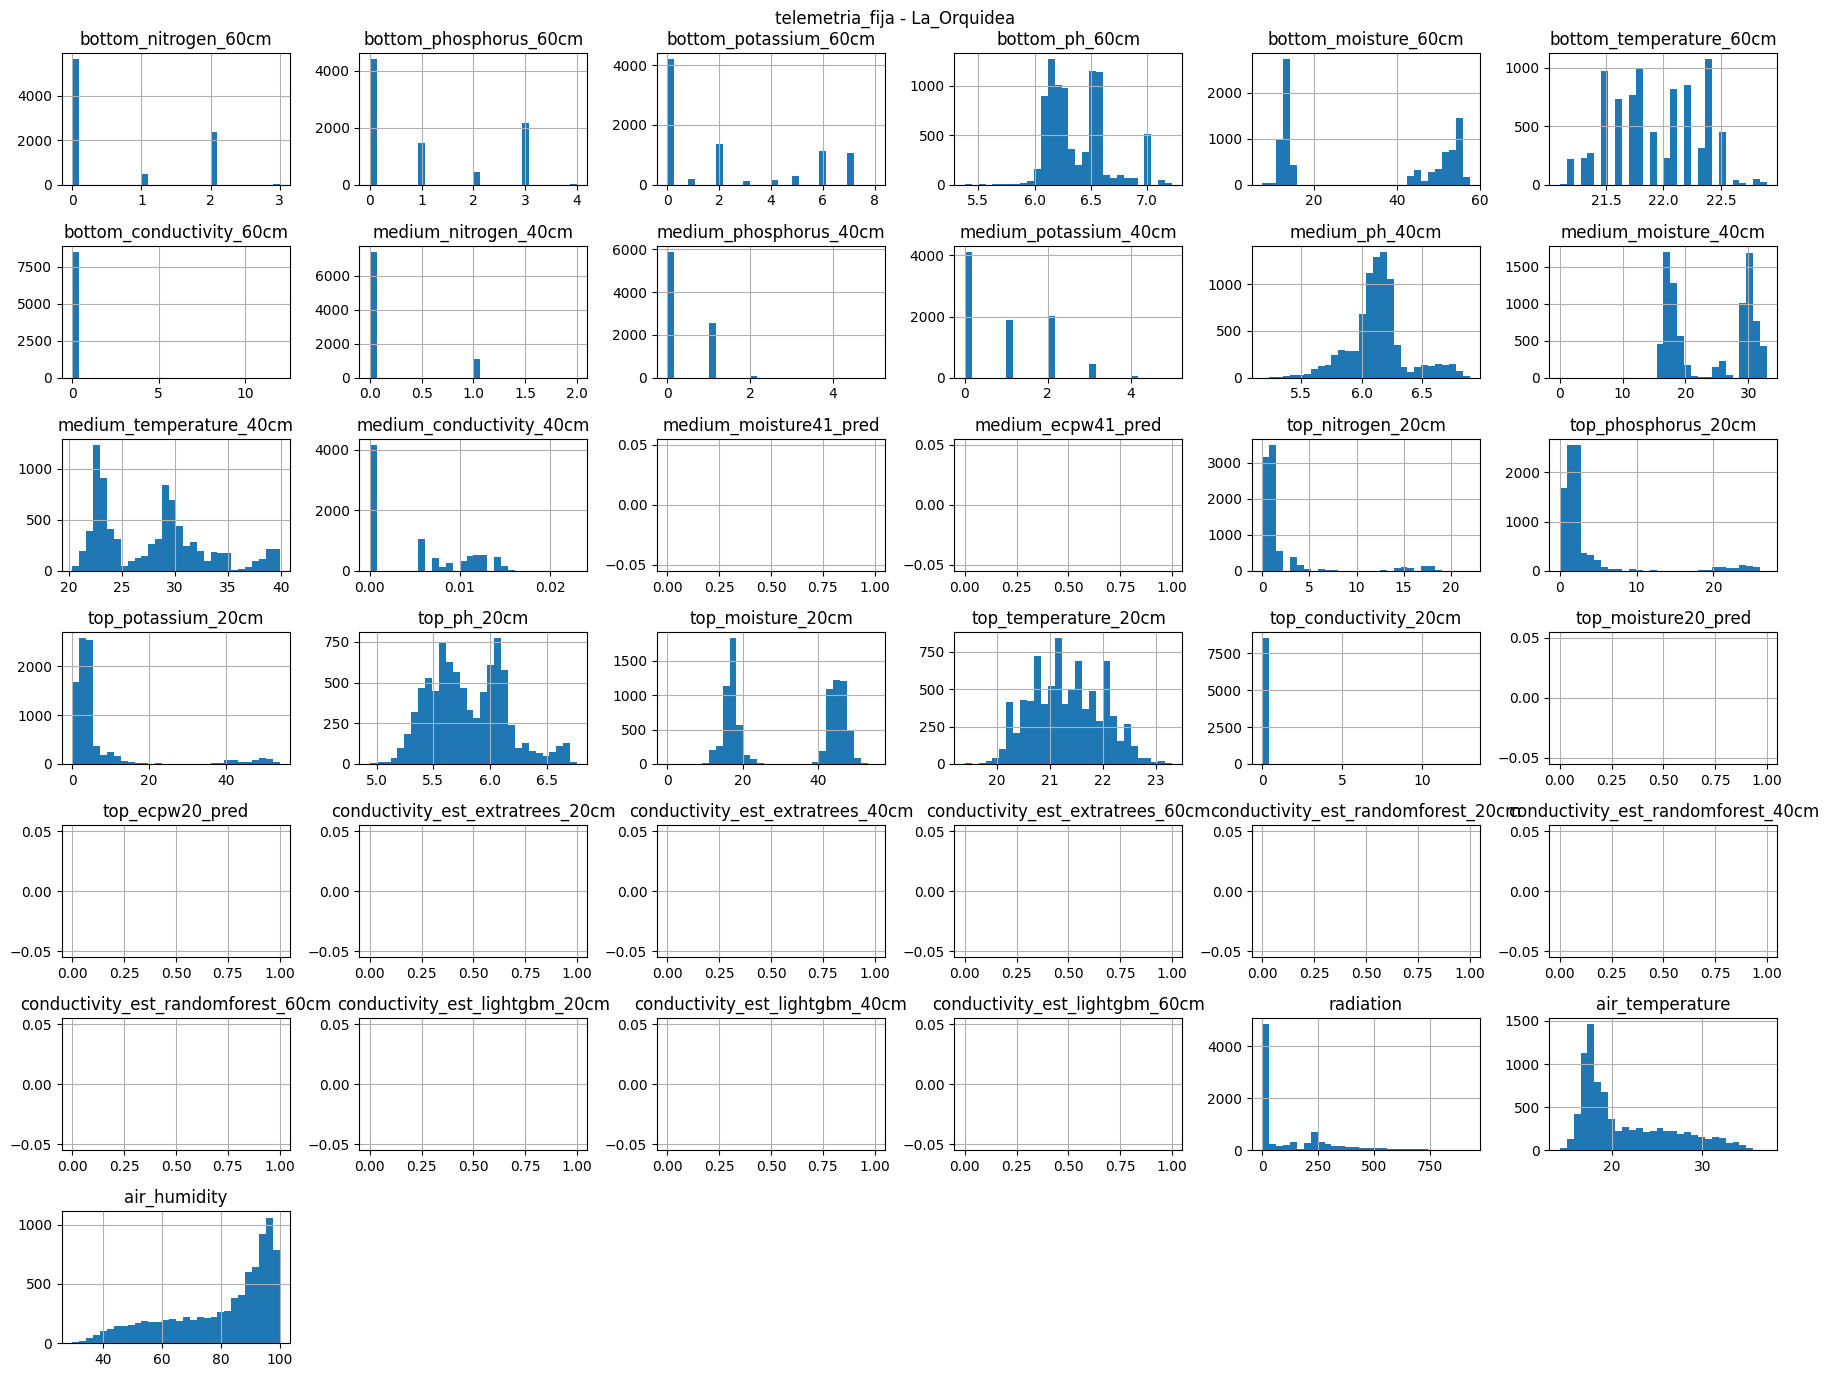

## telemetria_fija - Venecia 

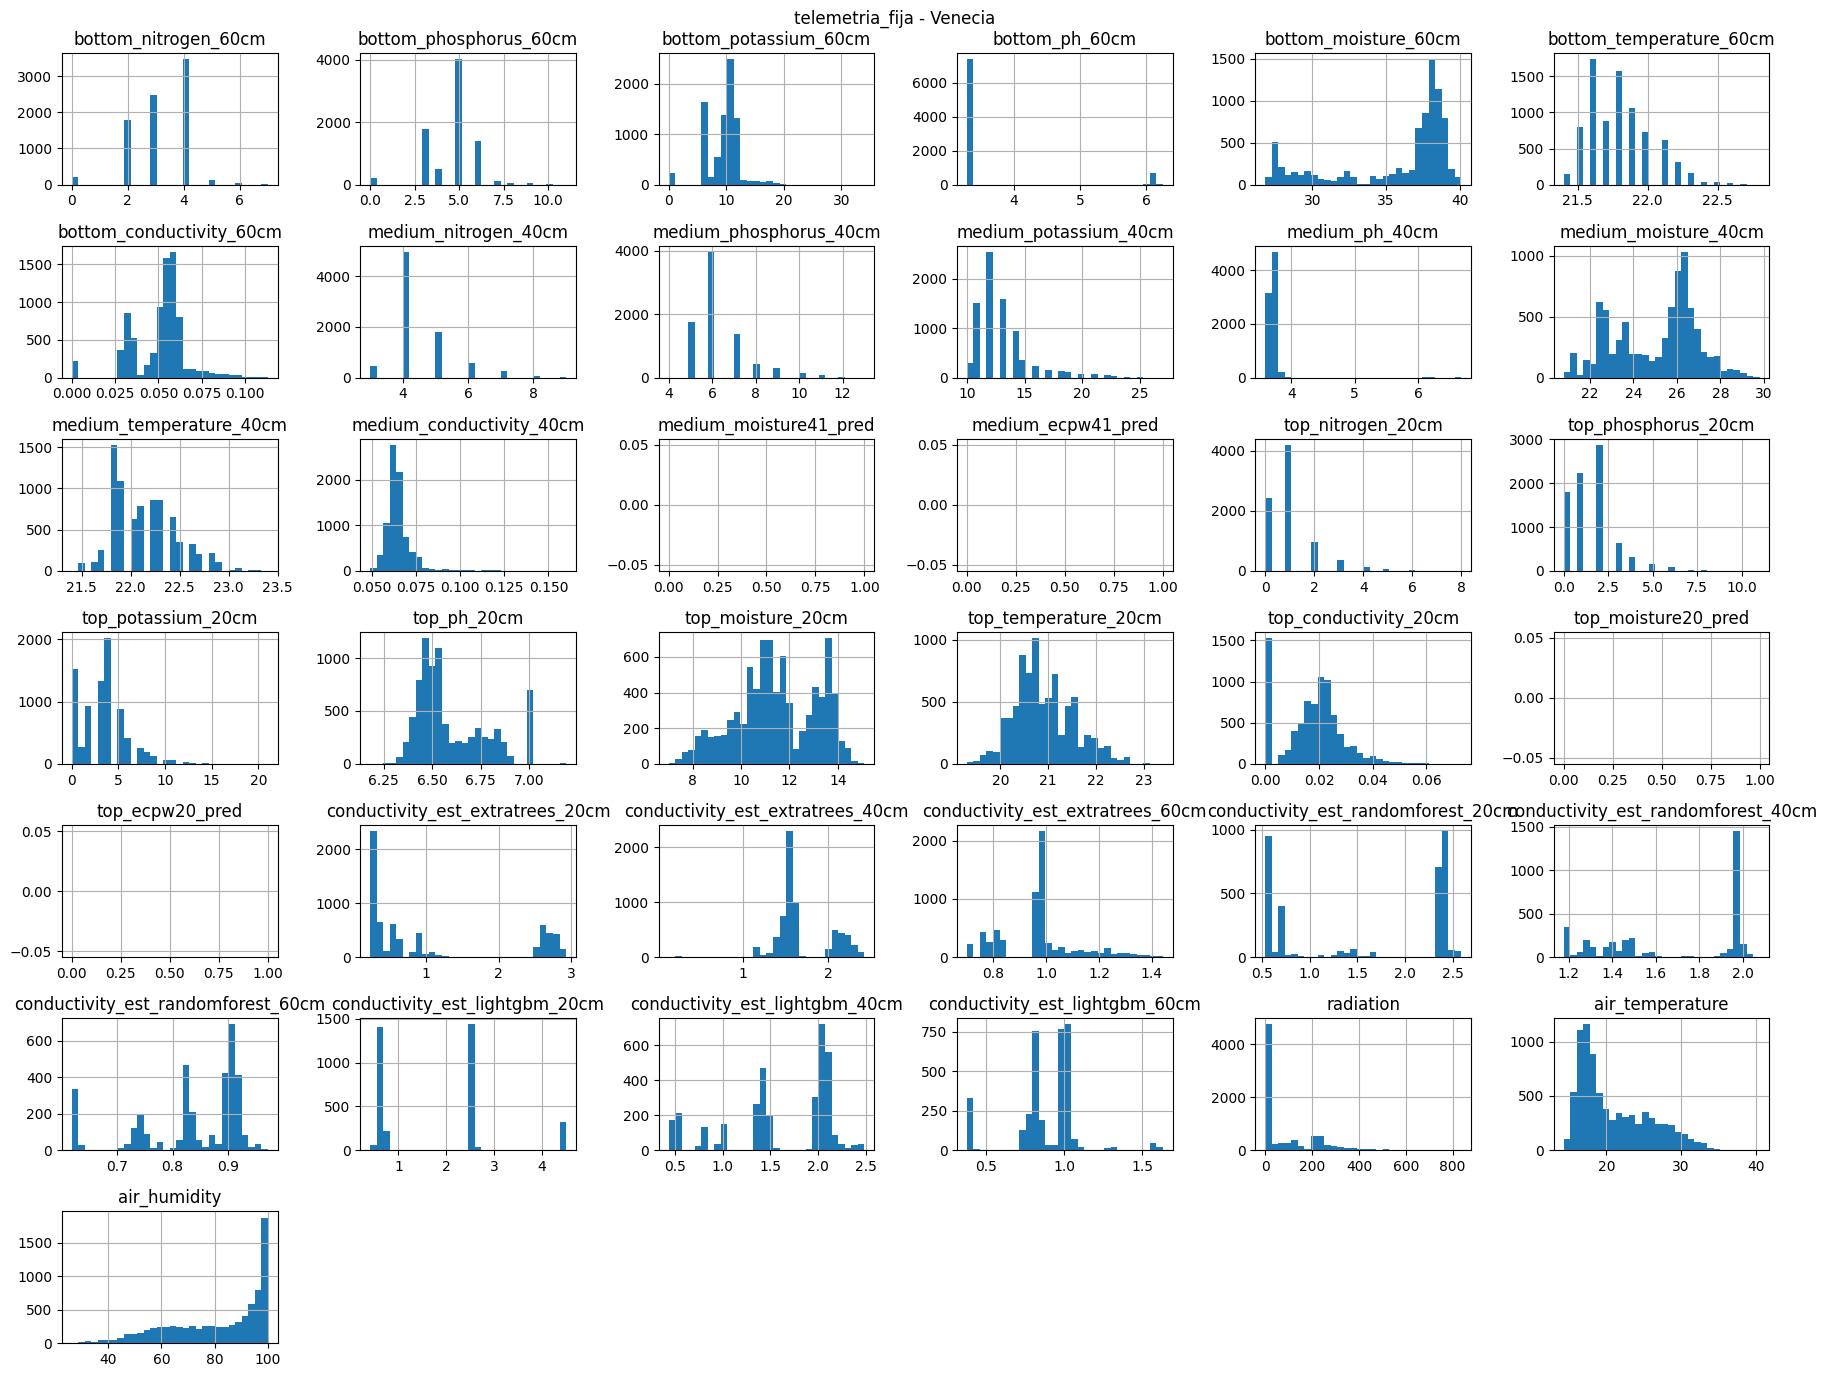

## telemetria_fija - Puerto_Arturo 

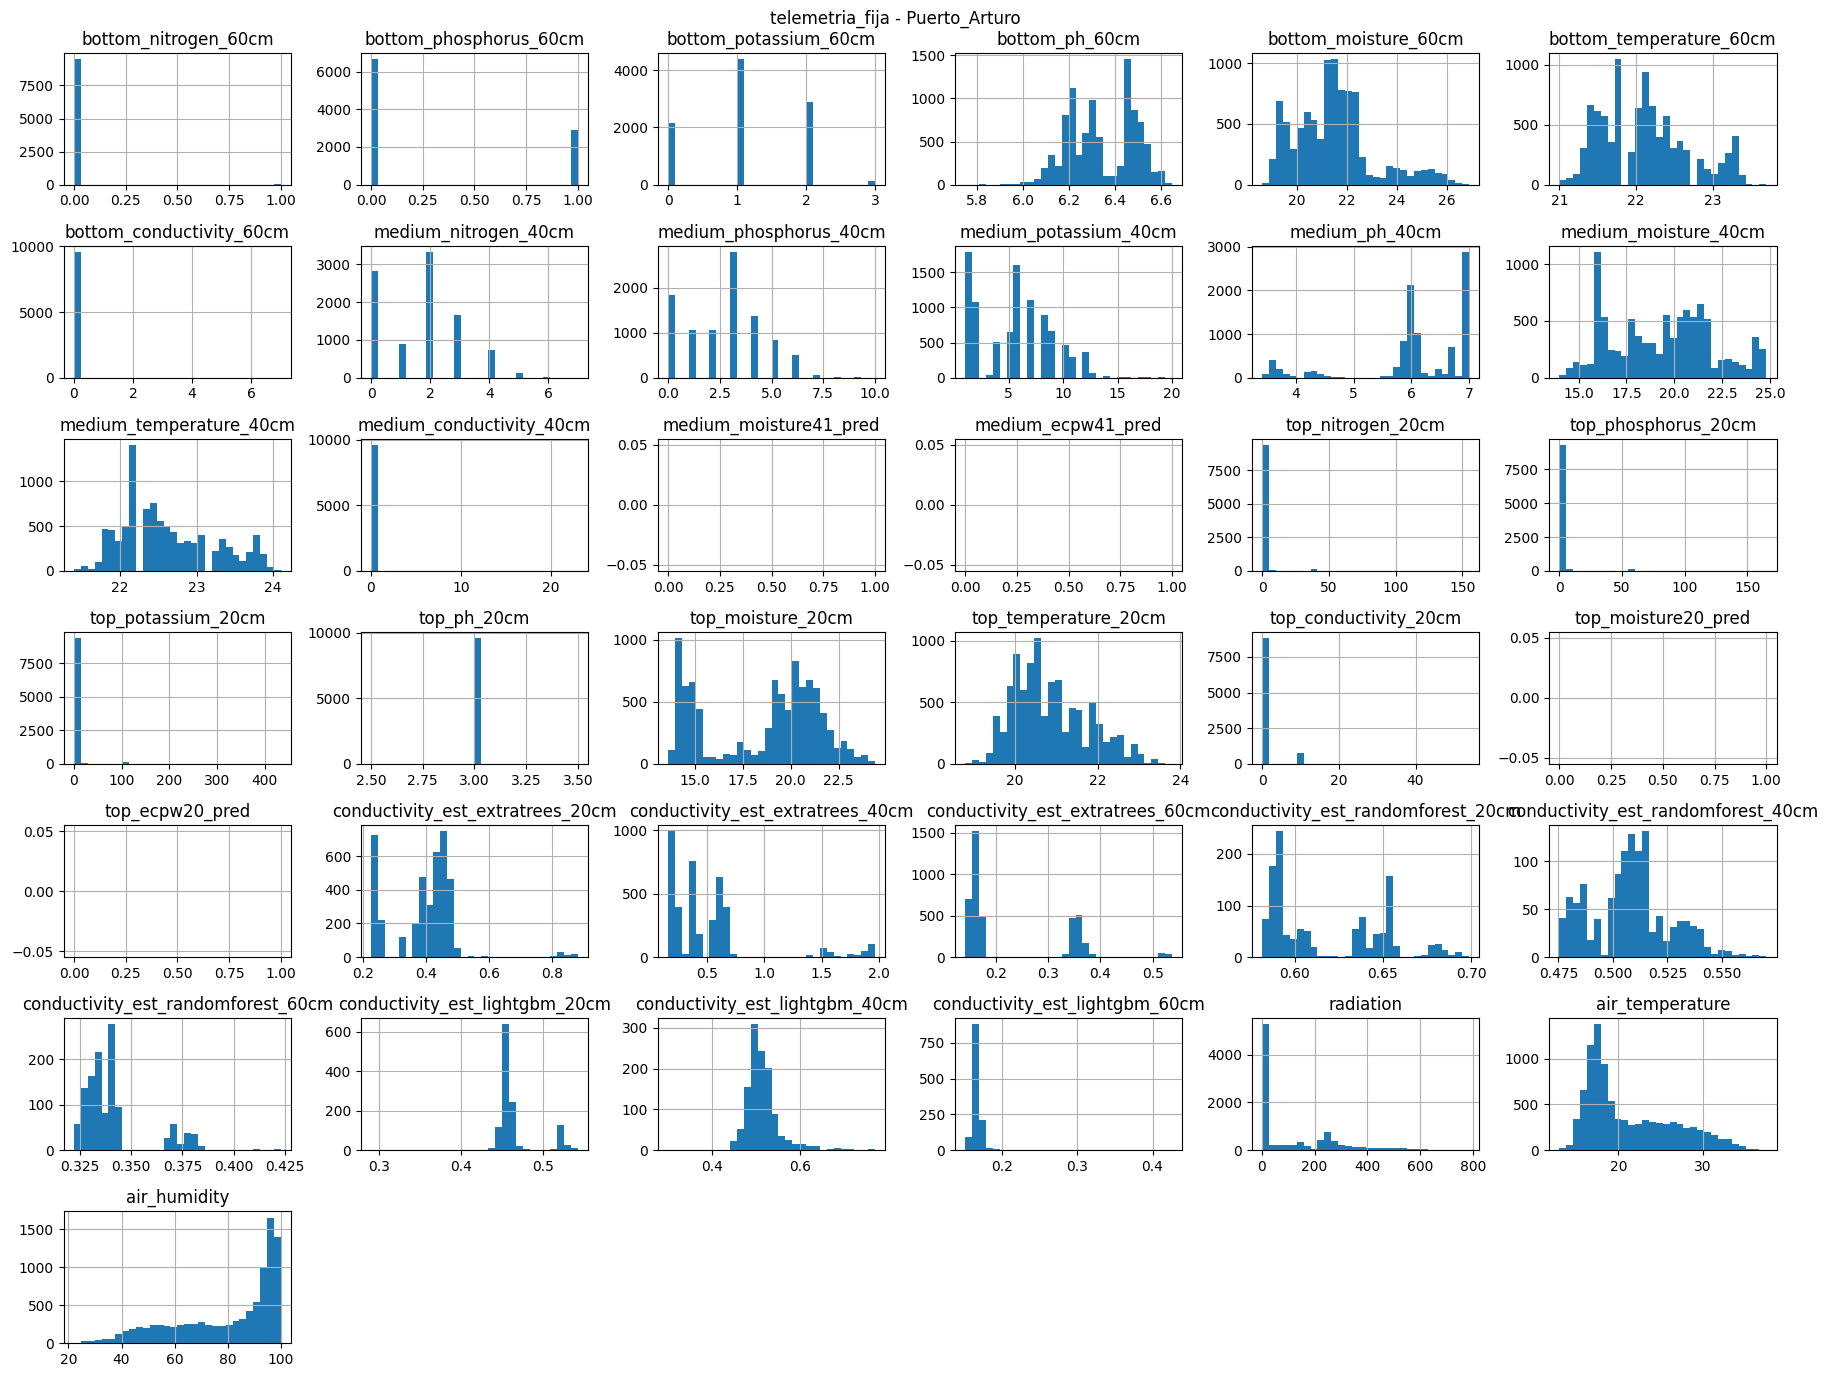

In [23]:
histogramas(BD_FIJA_FILTERED, NOMBRE_BD_FIJA)

## cropx - La_Orquidea 

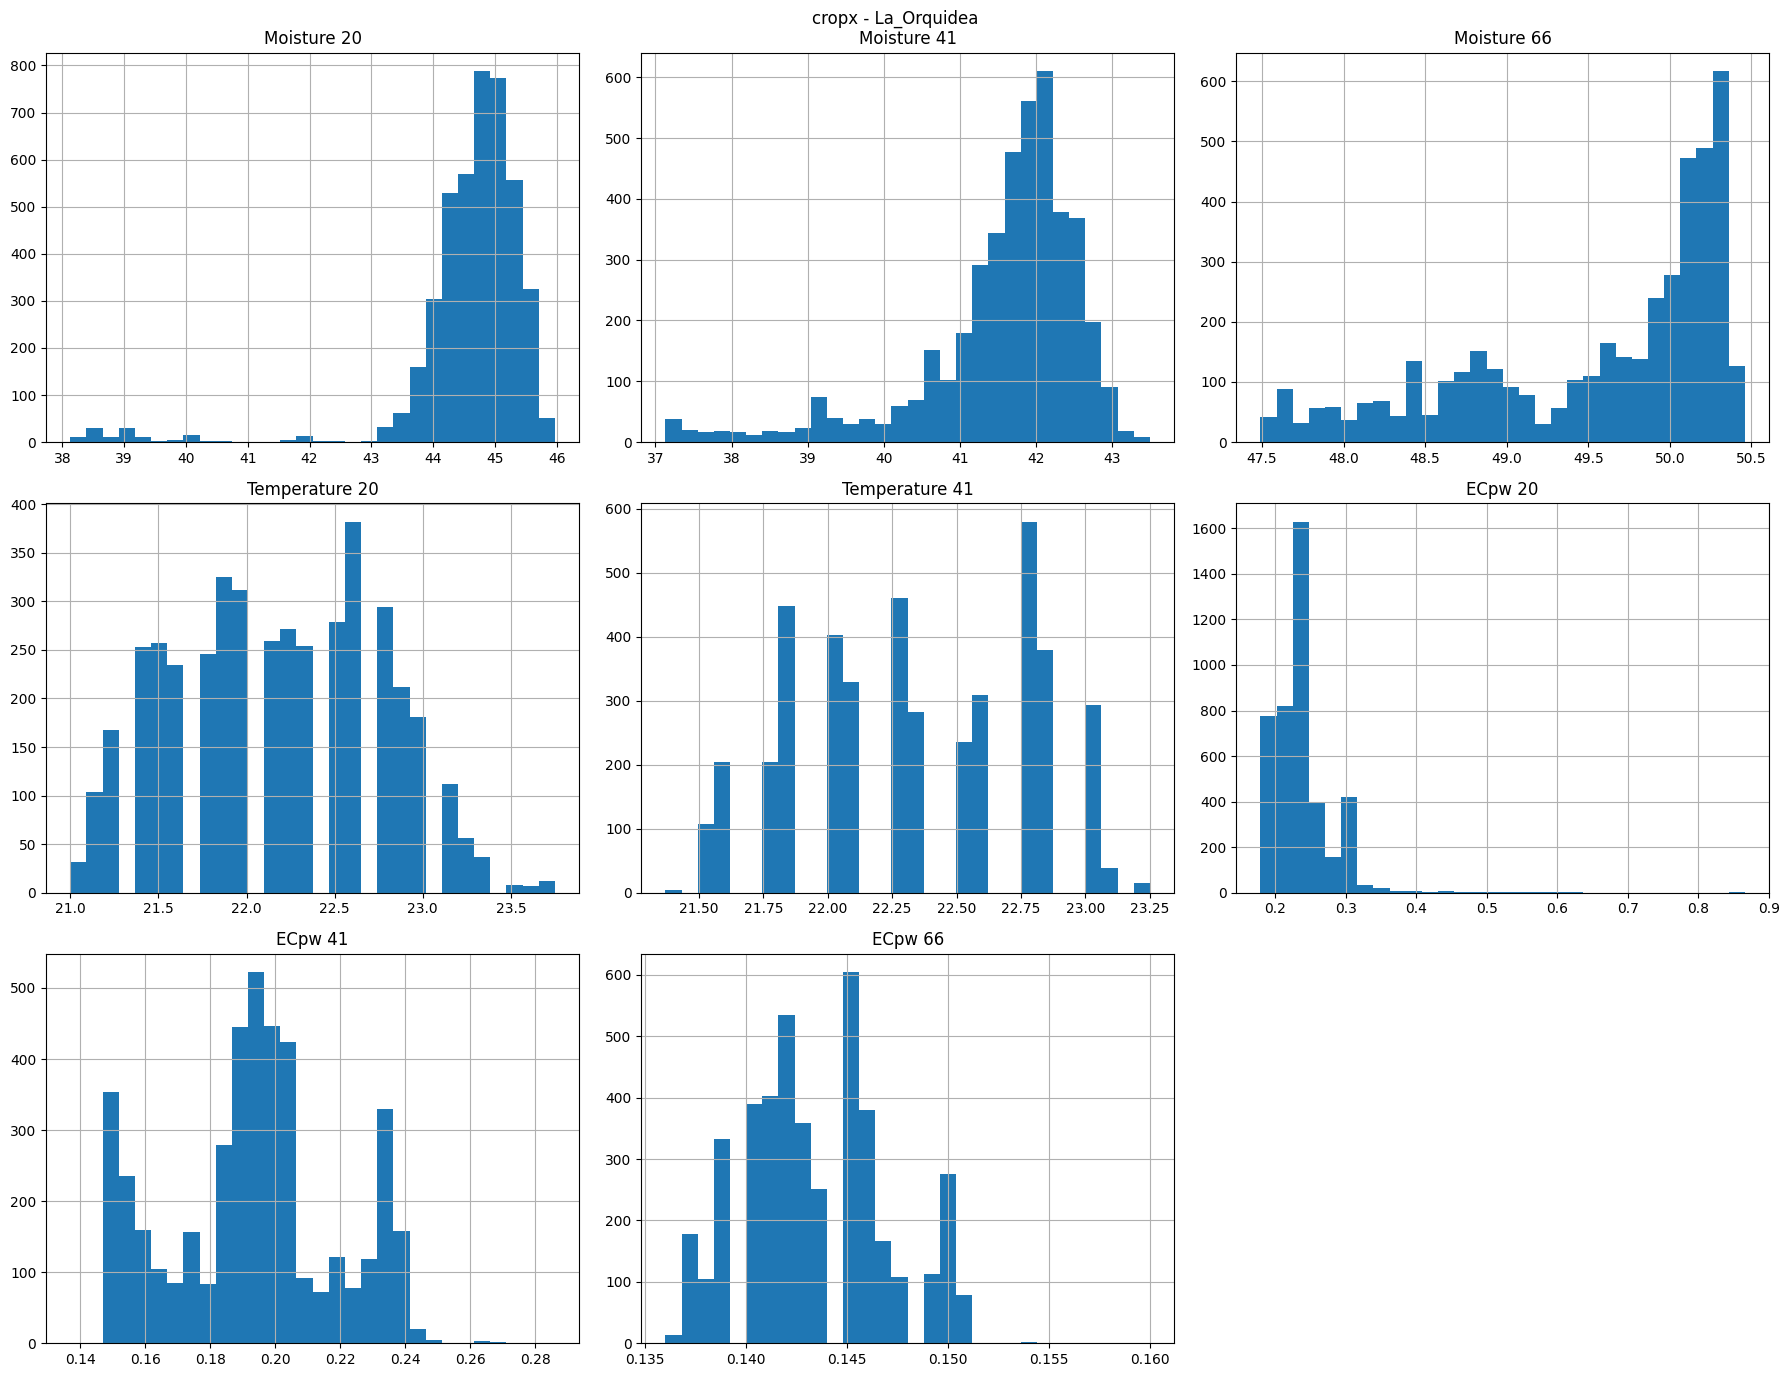

## cropx - Venecia 

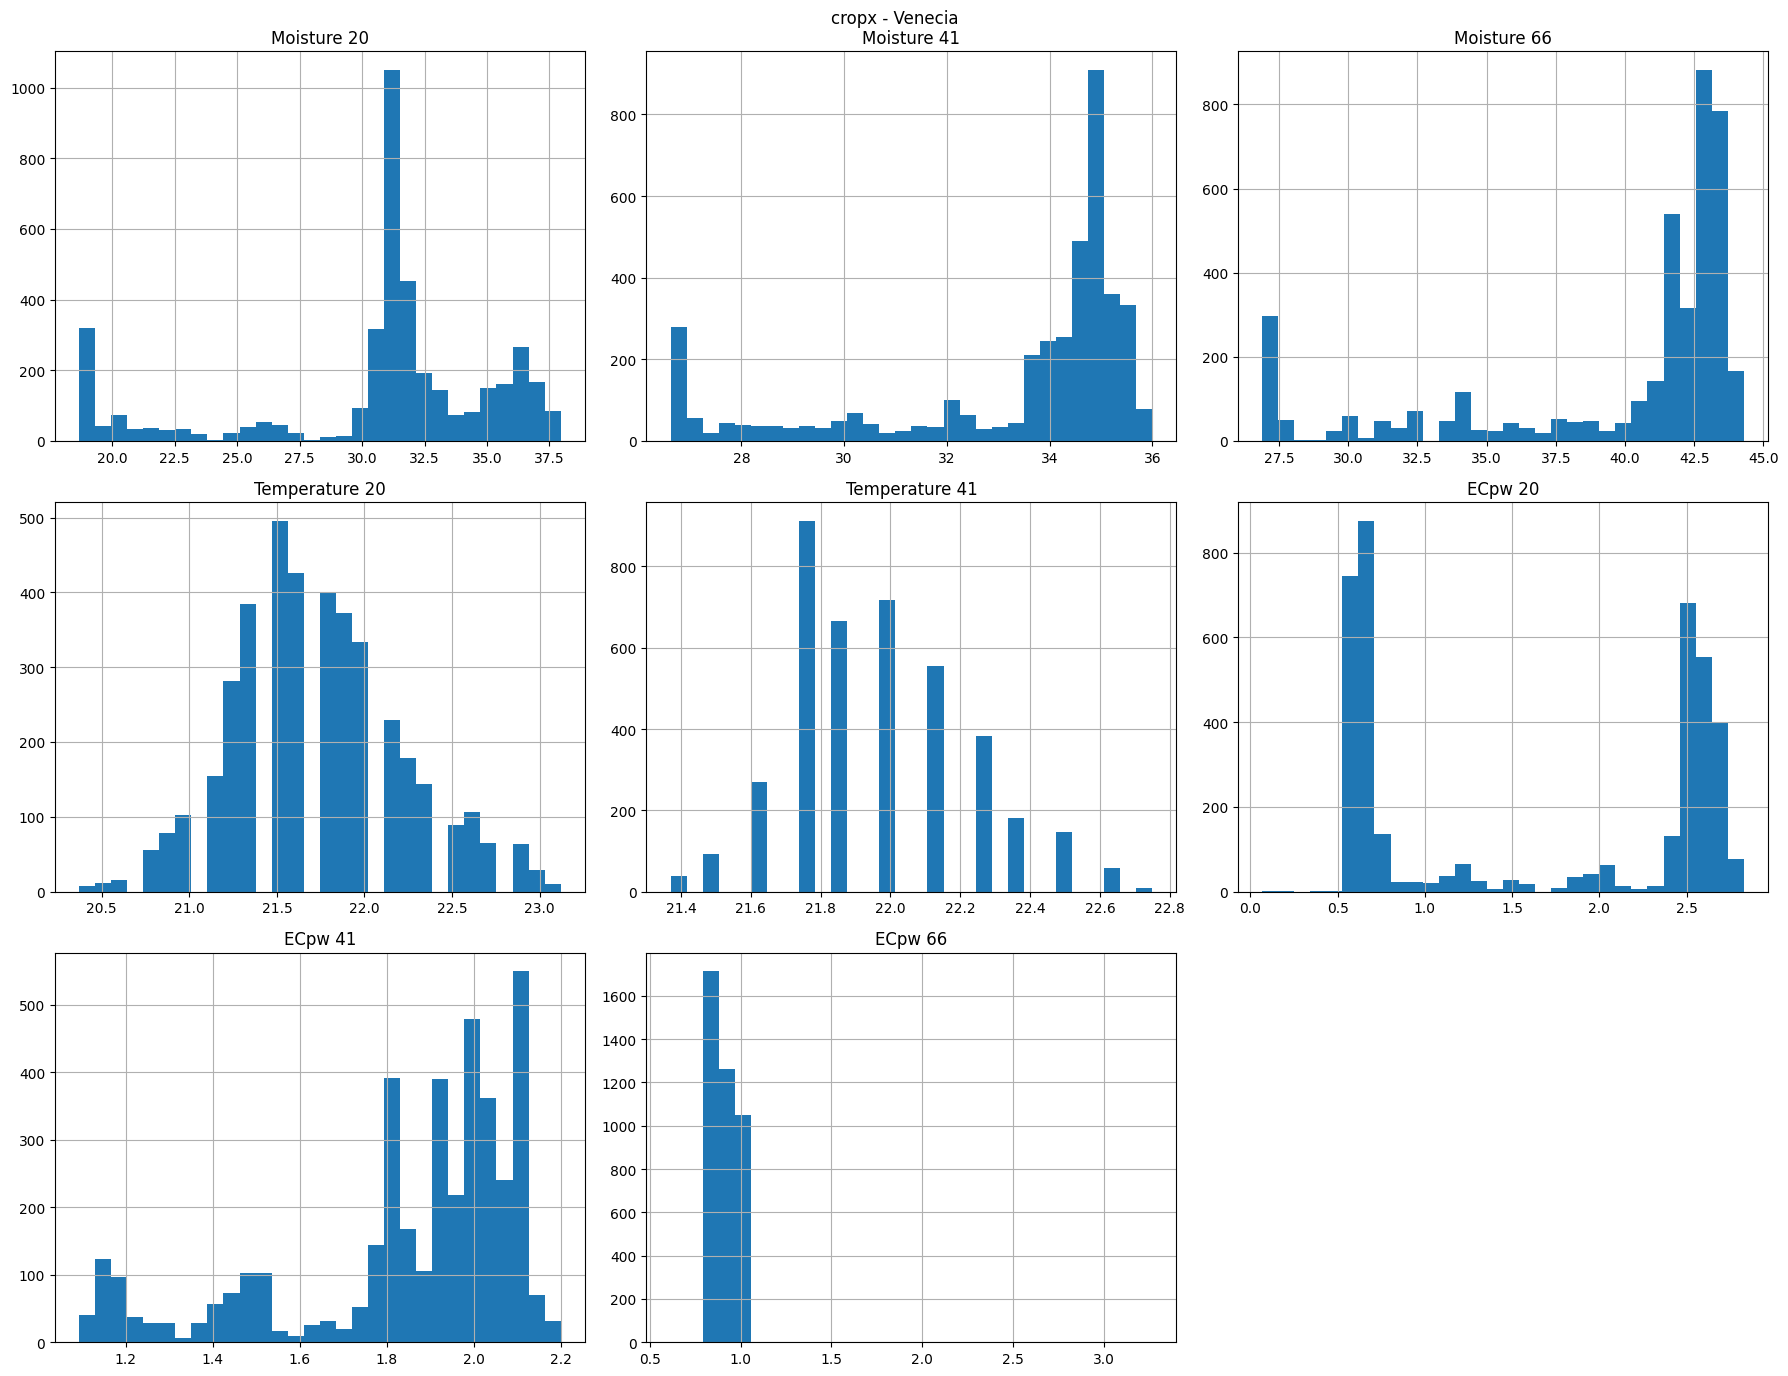

## cropx - Puerto_Arturo 

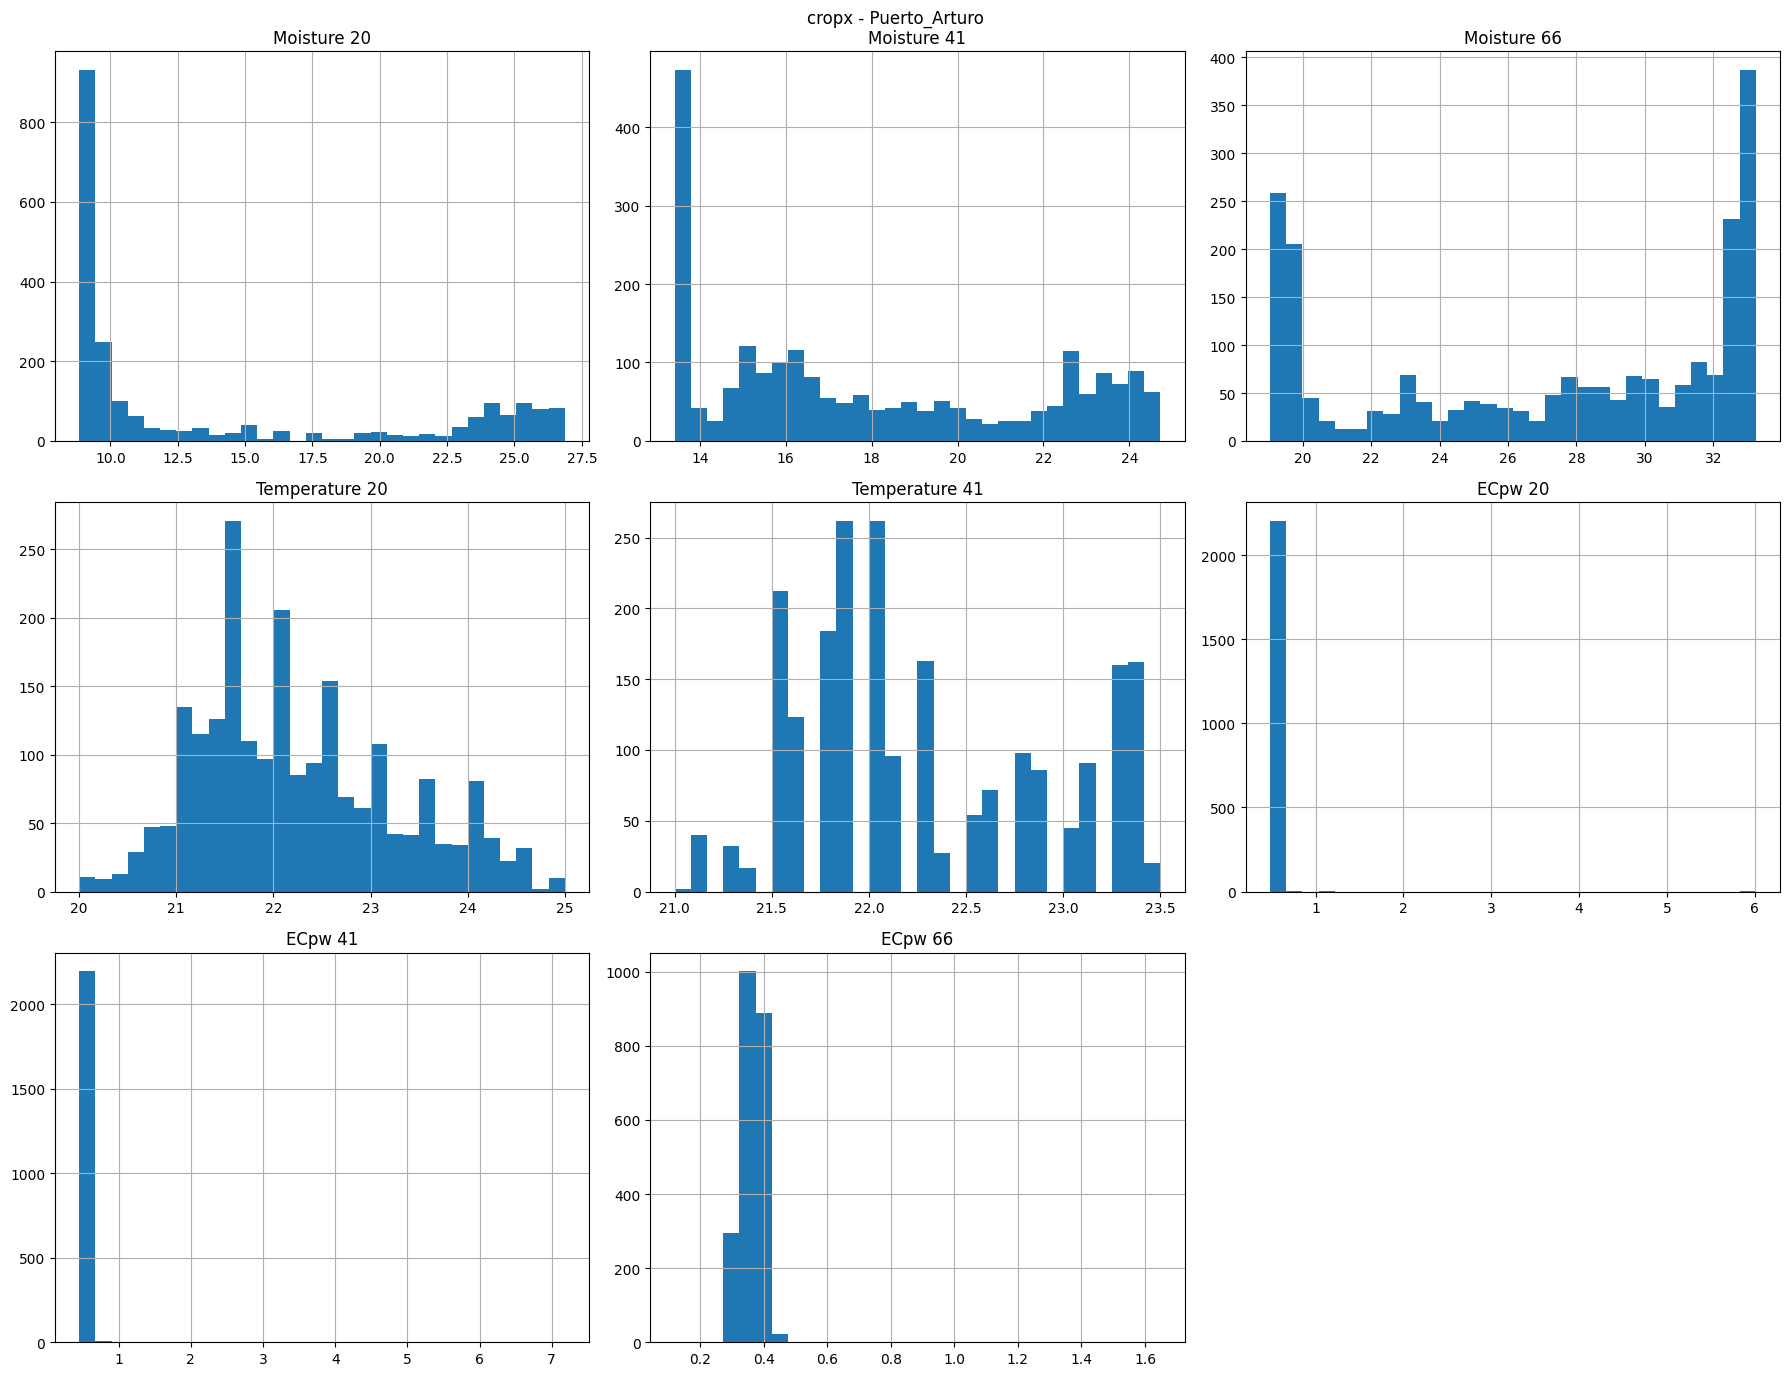

In [24]:
histogramas(BD_CROPX, NOMBRE_BD_CROPX)